<a href="https://colab.research.google.com/github/Lourdes-Churacutipa/Repositorio-de-lourdes/blob/main/CDA_Piura_Proyecto_Integrador_final_CORREGIDO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Integrador CDA — 1ª Entrega del TF
## El Niño y la lluvia en Piura: ¿qué índice ENSO la explica mejor y cambió la relación con el tiempo?

**Universidad de Ingeniería y Tecnología — UTEC · Curso: Ciencia de Datos Ambientales**

**Contenido (según el enunciado):** 1) tema · 2) base de datos principal y complementarias · 3) análisis exploratorio · 4) datos limpios · 5) gráficos.

## Problema, indicadores e hipótesis

**Problema.** Piura sufre lluvias extremas ligadas a El Niño (1982/83, 1997/98, 2017, 2023), pero no todos los eventos son iguales: unos se forman en el Pacífico central y otros solo frente a la costa de Perú. Una sola etiqueta "El Niño" puede esconder esas diferencias.

**Pregunta.** ¿Qué índice ENSO (**ICEN, ONI, E o C**) se relaciona mejor con la lluvia de Piura y cambió esa relación entre 1982-1999 y 2000-2025?

| Indicador | Definición | Unidad |
|---|---|---|
| Lluvia mensual | PISCO PP V3, promedio del departamento de Piura | mm/mes |
| Lluvia de temporada húmeda | Suma dic-may (año de término de la temporada) | mm |
| Días de lluvia extrema | Días de dic-may con lluvia > percentil 95 | días/temporada |
| Anomalía de lluvia | (observada − normal 1991-2020) / normal × 100 | % |

**H1.** Los índices ligados a la costa (**ICEN y E**) se relacionan más con la lluvia de Piura que los del Pacífico central (**ONI y C**).  
**H2.** La relación entre índices ENSO y lluvia cambió entre 1982-1999 y 2000-2025.

> **Cómo ejecutar:** deja en la misma carpeta (o sube a Colab) los CSV de PISCO, los 3 TXT de índices y, para las secciones opcionales, el GeoJSON de la cuenca y los TXT de estaciones SENAMHI. Las secciones opcionales se omiten solas si faltan sus archivos. Luego: *Entorno de ejecución → Ejecutar todo*.

## 1. Paquetes y carpeta de trabajo

In [ ]:
import os, re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})

CARPETA = '.'                      # carpeta con los archivos de datos
SALIDA = 'RESULTADOS_CDA_PIURA'    # carpeta de resultados
ARCHIVO_CUENCA = 'PIURA_SHU_CUENCA.geojson'
USAR_EARTH_ENGINE = False          # True solo si tienes Earth Engine autenticado (opcional)

os.makedirs(SALIDA, exist_ok=True)
def ruta(nombre): return os.path.join(CARPETA, nombre)

print('Archivos en la carpeta:', len(os.listdir(CARPETA)))

Archivos en la carpeta: 40


## 2. Fuentes de datos

| Tipo | Fuente | Variable | Periodo | Resolución |
|---|---|---|---|---|
| **Principal** | PISCO PP V3 (SENAMHI) | Precipitación (mm) | 1981-2025 | diaria y mensual |
| Complementaria | PISCO PP V2.1 | Precipitación, versión anterior (validación) | 1981-2016 | diaria y mensual |
| Complementaria | PISCO TN / TX V1.2 | Temperatura mínima / máxima (°C) | 1981-2020 | diaria y mensual |
| Complementaria | PISCO PET V1.1 | Evapotranspiración potencial (mm) | 1981-2016 | diaria y mensual |
| Complementaria | Estaciones SENAMHI | Lluvia y temperatura diarias | ~1961-2015 | diaria |
| Complementaria | Cuenca del río Piura (GeoJSON) | Área de estudio | — | polígono |
| **Índice ENSO** | ICEN (ENFEN, 2024) | Anomalía de TSM costera | 1950-2026 | mensual |
| **Índice ENSO** | ONI (NOAA) | Anomalía de TSM Niño 3.4 | 1950-2026 | trimestres móviles |
| **Índice ENSO** | E y C (Takahashi et al., 2011) | Modos Pacífico este y central | 1880-2020 | mensual |

**Alcance espacial.** Los CSV de PISCO ya vienen resumidos como **una sola serie para el polígono del departamento de Piura**, no para la cuenca del río Piura. Todo lo que se diga con PISCO describe el departamento. Los **índices ENSO no son de Piura**: son series del océano Pacífico y se unen a la lluvia **por fecha**.

## 3. Área de estudio (opcional: requiere el GeoJSON de la cuenca)

Sistema de coordenadas: EPSG:4326 | unidades: 18
Unidades seleccionadas: 9 | Área de estudio (km²): 10910.03


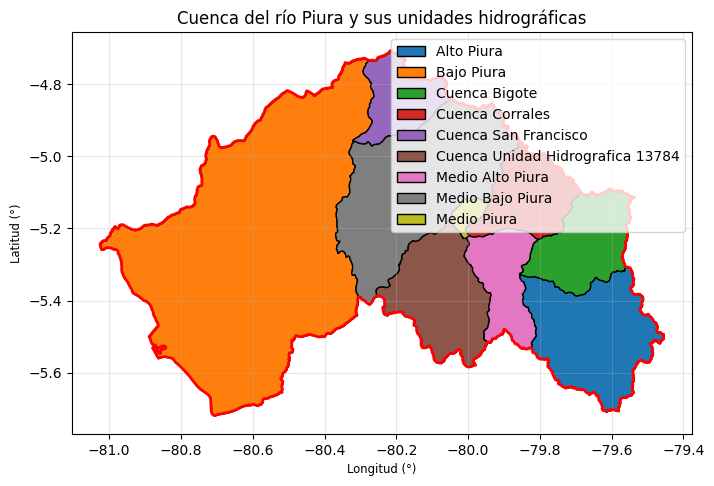

In [ ]:
cuenca = None
unidades_piura = None
try:
    import geopandas as gpd
    if os.path.exists(ruta(ARCHIVO_CUENCA)):
        unidades = gpd.read_file(ruta(ARCHIVO_CUENCA))
        print('Sistema de coordenadas:', unidades.crs, '| unidades:', len(unidades))
        codigos_piura = [13781, 13782, 13783, 13784, 13785, 13786, 13787, 13788, 13789]
        unidades_piura = unidades[unidades['CODIGO'].astype(int).isin(codigos_piura)].copy()
        cuenca = unidades_piura.dissolve()
        area_km2 = cuenca.to_crs('EPSG:32717').geometry.area.sum() / 1e6
        print('Unidades seleccionadas:', len(unidades_piura), '| Área de estudio (km²):', round(area_km2, 2))

        ax = unidades_piura.plot(figsize=(8, 8), column='Nombre_UH', legend=True, edgecolor='black')
        cuenca.boundary.plot(ax=ax, color='red', linewidth=2)
        plt.title('Cuenca del río Piura y sus unidades hidrográficas')
        plt.xlabel('Longitud (°)'); plt.ylabel('Latitud (°)')
        plt.show()
    else:
        print('Sección omitida: no se encontró', ARCHIVO_CUENCA)
except ImportError:
    print('Sección omitida: geopandas no está instalado (pip install geopandas).')

In [ ]:
import ee
import geemap

# Inicializar Earth Engine
ee.Authenticate()
ee.Initialize(project= 'utec-ingambiental-01')

# Mapa
#Map = geemap.Map()
Map = geemap.Map(center=[-9.5, -75.0], zoom=7,basemap="Esri.WorldTopoMap")
# 1. Mapa del Perú de fondo: límites departamentales
peru = ee.FeatureCollection('FAO/GAUL/2015/level1') \
    .filter(ee.Filter.eq('ADM0_NAME', 'Peru'))

Map.addLayer(
    peru.style(**{
        'color': '808080',
        'fillColor': 'FFFFFF00',
        'width': 1
    }),
    {},
    'Departamentos del Perú'
)

# 2. Resaltar Piura
piura = peru.filter(ee.Filter.eq('ADM1_NAME', 'Piura'))

Map.addLayer(
    piura.style(**{
        'color': 'D97706',
        'fillColor': 'FDE68A55',
        'width': 2
    }),
    {},
    'Departamento de Piura'
)

# 3. Convertir el GeoDataFrame local (unidades_piura) a ee.FeatureCollection
# Esto evita tener que cargar el archivo manualmente como Asset en Earth Engine
try:
    # 'unidades_piura' es el GeoDataFrame de la sección 2
    cuenca_ee = geemap.gdf_to_ee(unidades_piura)

    Map.addLayer(
        cuenca_ee.style(**{
            'color': 'DC2626',
            'fillColor': '00000000',
            'width': 2
        }),
        {},
        'Unidades hidrográficas de Piura (Local GeoJSON)'
    )
except NameError:
    print("Por favor, ejecuta primero la celda de la sección 2 para definir 'unidades_piura'")

Map.centerObject(piura, 6)
Map

## 4. Estaciones SENAMHI (complementaria, opcional)

Se cargan los TXT diarios de las estaciones, se limpian y se agregan a escala mensual. Más adelante se comparan con PISCO (sección 8.5).

In [ ]:
archivos_txt = glob.glob(ruta('*.txt'))
# Los TXT de índices contienen "ndice" en el nombre (Índice / Índices); el resto son estaciones
archivos_estaciones = [a for a in archivos_txt if 'ndice' not in os.path.basename(a)]
print('Estaciones encontradas:', len(archivos_estaciones))

estaciones = pd.DataFrame()
mensual_estaciones = pd.DataFrame()
if archivos_estaciones:
    columnas = ['anio', 'mes', 'dia', 'pp_mm', 'tmax_c', 'tmin_c']
    lista = []
    for archivo in archivos_estaciones:
        d = pd.read_csv(archivo, sep=r'\s+', header=None, names=columnas, usecols=range(6), engine='python')
        d['estacion'] = os.path.splitext(os.path.basename(archivo))[0]
        lista.append(d)
    estaciones = pd.concat(lista, ignore_index=True)
    estaciones['fecha'] = pd.to_datetime(dict(year=estaciones['anio'], month=estaciones['mes'], day=estaciones['dia']), errors='coerce')
    estaciones = estaciones.replace([-99.9, -999, -9999, -99], np.nan).sort_values(['estacion', 'fecha'])

    print('Registros:', len(estaciones), '| Estaciones:', estaciones['estacion'].nunique())
    print('Fechas inválidas:', estaciones['fecha'].isna().sum(),
          '| Duplicados estación-fecha:', estaciones.duplicated(['estacion', 'fecha']).sum(),
          '| Precipitación negativa:', (estaciones['pp_mm'] < 0).sum())
    resumen_estaciones = estaciones.groupby('estacion').agg(
        registros=('fecha', 'count'), inicio=('fecha', 'min'), fin=('fecha', 'max'),
        faltantes_pp=('pp_mm', lambda x: x.isna().sum()), pp_max_mm=('pp_mm', 'max')).reset_index()
    display(resumen_estaciones)
    resumen_estaciones.to_csv(os.path.join(SALIDA, '01_resumen_estaciones.csv'), index=False)
else:
    print('Sección omitida: no hay TXT de estaciones en la carpeta.')

Estaciones encontradas: 20
Registros: 357524 | Estaciones: 20
Fechas inválidas: 0 | Duplicados estación-fecha: 0 | Precipitación negativa: 0


,estacion,registros,inicio,fin,faltantes_pp,pp_max_mm
0,AYABACA,18809,1963-01-01,2014-06-30,674,124.3
1,BERNAL,18505,1963-11-01,2014-06-30,1101,123.2
2,CHULUCANAS,15521,1972-01-02,2014-06-30,2873,202.5
3,CHUSIS,18441,1963-11-04,2014-04-30,2594,136.2
4,HACIENDA BIGOTE,18294,1963-12-01,2013-12-31,1061,240.0
5,HACIENDA SHUMAYA,18324,1963-11-01,2013-12-31,393,100.8
6,HUARMACA,19006,1963-10-19,2015-10-31,705,145.2
7,LA ESPERANZA,18020,1966-07-01,2015-10-31,869,134.8
8,LANCONES,18566,1963-09-01,2014-06-30,489,193.8
9,MALLARES,19539,1961-01-01,2014-06-30,4271,201.0


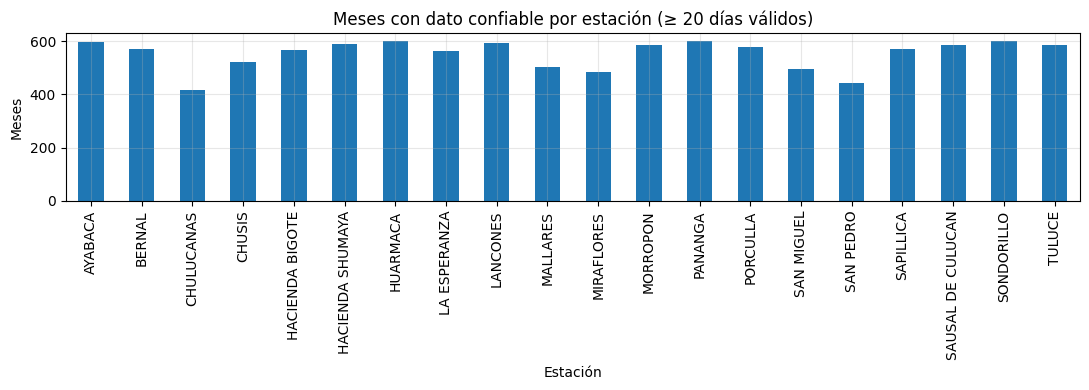

In [ ]:
# Limpieza de estaciones y paso a lluvia mensual
if len(estaciones) > 0:
    estaciones = estaciones.dropna(subset=['fecha']).drop_duplicates(['estacion', 'fecha'], keep='first')
    estaciones.loc[estaciones['pp_mm'] < 0, 'pp_mm'] = np.nan
    # Los extremos se conservan (son parte del fenómeno); solo se listan para revisión
    extremos = estaciones.sort_values('pp_mm', ascending=False).groupby('estacion').head(3)
    extremos[['estacion', 'fecha', 'pp_mm']].sort_values(['estacion', 'pp_mm'], ascending=[True, False]).to_csv(
        os.path.join(SALIDA, '02_extremos_estaciones.csv'), index=False)

    estaciones['mes_fecha'] = estaciones['fecha'].dt.to_period('M').dt.to_timestamp()
    mensual_estaciones = estaciones.groupby(['estacion', 'mes_fecha']).agg(
        pp_mensual_mm=('pp_mm', lambda x: x.sum(min_count=1)),
        dias_validos=('pp_mm', 'count')).reset_index().rename(columns={'mes_fecha': 'fecha'})
    # Un mes con menos de 20 días válidos no es confiable: se anula
    mensual_estaciones.loc[mensual_estaciones['dias_validos'] < 20, 'pp_mensual_mm'] = np.nan
    mensual_estaciones.to_csv(os.path.join(SALIDA, '03_estaciones_mensuales.csv'), index=False)

    mensual_estaciones.groupby('estacion')['pp_mensual_mm'].count().plot(kind='bar', figsize=(11, 4))
    plt.title('Meses con dato confiable por estación (≥ 20 días válidos)')
    plt.ylabel('Meses'); plt.xlabel('Estación'); plt.xticks(rotation=90); plt.tight_layout(); plt.show()

Estaciones con coordenadas dentro de la cuenca: 8 -> ['CHULUCANAS', 'CHUSIS', 'HACIENDA BIGOTE', 'HUARMACA', 'MIRAFLORES', 'MORROPON', 'SAN MIGUEL', 'SAN PEDRO']
Estaciones FUERA del polígono (no se usan en 8.5): ['HACIENDA SHUMAYA']


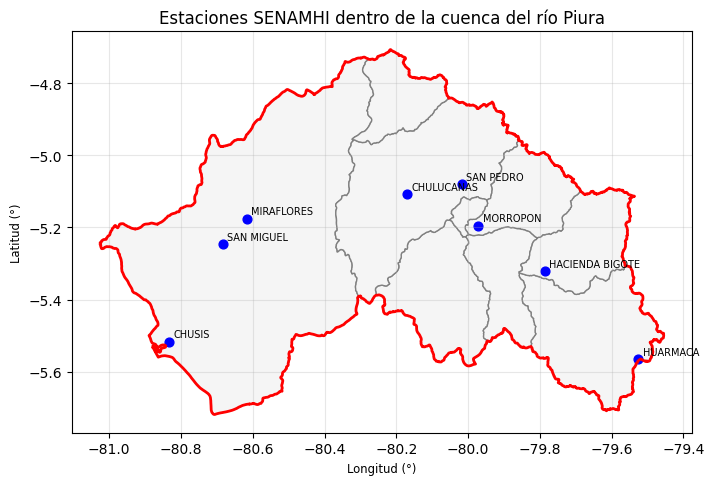

In [ ]:
# Estaciones dentro de la cuenca (solo si hay GeoJSON y geopandas)
estaciones_cuenca = estaciones
if len(estaciones) > 0 and cuenca is not None:
    coordenadas = pd.DataFrame({
        'estacion': ['HUARMACA', 'MORROPON', 'CHULUCANAS', 'MIRAFLORES', 'SAN MIGUEL', 'CHUSIS',
                     'HACIENDA BIGOTE', 'HACIENDA SHUMAYA', 'SAN PEDRO'],
        'latitud': [-5.565861, -5.194644, -5.108444, -5.175278, -5.246186, -5.516944, -5.320889, -5.364919, -5.079536],
        'longitud': [-79.525444, -79.971075, -80.169539, -80.616542, -80.684250, -80.833611, -79.785686, -79.359931, -80.016214]})
    puntos = gpd.GeoDataFrame(coordenadas, geometry=gpd.points_from_xy(coordenadas['longitud'], coordenadas['latitud']), crs='EPSG:4326')
    dentro = gpd.sjoin(puntos, cuenca.to_crs('EPSG:4326')[['geometry']], how='inner', predicate='within')
    print('Estaciones con coordenadas dentro de la cuenca:', len(dentro), '->', sorted(dentro['estacion']))
    print('Estaciones FUERA del polígono (no se usan en 8.5):', sorted(set(coordenadas['estacion']) - set(dentro['estacion'])))
    estaciones_cuenca = estaciones[estaciones['estacion'].isin(dentro['estacion'])]

    ax = unidades_piura.to_crs('EPSG:4326').plot(figsize=(8, 8), color='whitesmoke', edgecolor='gray')
    cuenca.boundary.plot(ax=ax, color='red', linewidth=2)
    dentro.plot(ax=ax, color='blue', markersize=40)
    for _, r in dentro.iterrows():
        ax.annotate(r['estacion'], (r['longitud'], r['latitud']), fontsize=7, xytext=(3, 3), textcoords='offset points')
    plt.title('Estaciones SENAMHI dentro de la cuenca del río Piura')
    plt.xlabel('Longitud (°)'); plt.ylabel('Latitud (°)'); plt.show()

## 5. PISCO: carga, inspección y validación

In [ ]:
def cargar_pisco(nombre, columna):
    # Los CSV traen BOM (utf-8-sig); la 2ª columna lleva la unidad en el nombre
    d = pd.read_csv(ruta(nombre), encoding='utf-8-sig')
    unidad = re.search(r'\((.*?)\)', d.columns[1]).group(1)
    d.columns = ['fecha', columna]
    d['fecha'] = pd.to_datetime(d['fecha'], errors='coerce')
    d[columna] = pd.to_numeric(d[columna], errors='coerce')
    return d.dropna(subset=['fecha']).sort_values('fecha').set_index('fecha'), unidad

pp, u_pp = cargar_pisco('PISCO_PP_V3_MENSUAL_1981-2025.csv', 'pp_mm')
pp_d, _ = cargar_pisco('PISCO_PP_V3_DIARIA_1981-2025.csv', 'pp_mm')
pp21, _ = cargar_pisco('PISCO_PP_V21_MENSUAL_1981-2016.csv', 'pp_v21')
tn, u_t = cargar_pisco('PISCO_TN_V12_MENSUAL_1981-2020.csv', 'tmin_c')
tx, _ = cargar_pisco('PISCO_TX_V12_MENSUAL_1981-2020.csv', 'tmax_c')
pet, u_pet = cargar_pisco('PISCO_PET_V11_MENSUAL_1981-2016.csv', 'pet_mm')

series = {'PP V3 mensual': pp, 'PP V3 diaria': pp_d, 'PP V2.1 mensual': pp21,
          'TN mensual': tn, 'TX mensual': tx, 'PET mensual': pet}
inventario = pd.DataFrame({
    'unidad': [u_pp, u_pp, u_pp, u_t, u_t, u_pet],
    'inicio': [d.index.min().strftime('%Y-%m-%d') for d in series.values()],
    'fin': [d.index.max().strftime('%Y-%m-%d') for d in series.values()],
    'registros': [len(d) for d in series.values()],
    'nulos': [int(d.iloc[:, 0].isna().sum()) for d in series.values()],
    'fechas_duplicadas': [int(d.index.duplicated().sum()) for d in series.values()],
    'negativos': [int((d.iloc[:, 0] < 0).sum()) for d in series.values()]}, index=list(series.keys()))
inventario

,unidad,inicio,fin,registros,nulos,fechas_duplicadas,negativos
PP V3 mensual,mm,1981-01-01,2025-12-01,540,0,0,0
PP V3 diaria,mm,1981-01-01,2025-12-31,16436,0,0,0
PP V2.1 mensual,mm,1981-01-01,2016-12-01,432,0,0,0
TN mensual,°C,1981-01-01,2020-12-01,480,0,0,0
TX mensual,°C,1981-01-01,2020-12-01,480,0,0,0
PET mensual,mm,1981-01-01,2016-12-01,432,0,0,0


Diferencia máxima diaria vs mensual (mm): 5.684341886080802e-14
Meses en común: 432
Correlación V3 vs V2.1 -> Pearson: 0.988 | Spearman: 0.972
Sesgo medio V3 - V2.1 (mm/mes): 0.2


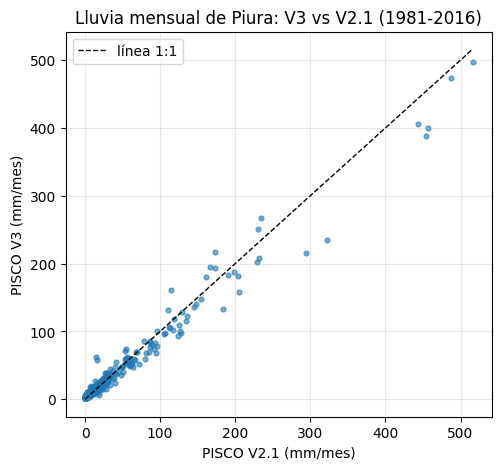

In [ ]:
# Validación 1: la suma diaria debe coincidir con la serie mensual
suma_diaria = pp_d['pp_mm'].resample('MS').sum()
print('Diferencia máxima diaria vs mensual (mm):', float((suma_diaria - pp['pp_mm']).abs().max()))

# Validación 2: V3 frente a la versión anterior (V2.1) en el periodo común
comun = pp.join(pp21, how='inner')
print('Meses en común:', len(comun))
print('Correlación V3 vs V2.1 -> Pearson:', round(comun['pp_mm'].corr(comun['pp_v21']), 3),
      '| Spearman:', round(comun['pp_mm'].corr(comun['pp_v21'], method='spearman'), 3))
print('Sesgo medio V3 - V2.1 (mm/mes):', round((comun['pp_mm'] - comun['pp_v21']).mean(), 2))

plt.figure(figsize=(5.5, 5))
plt.scatter(comun['pp_v21'], comun['pp_mm'], s=12, alpha=0.6)
lim = max(comun['pp_mm'].max(), comun['pp_v21'].max())
plt.plot([0, lim], [0, lim], 'k--', lw=1, label='línea 1:1')
plt.xlabel('PISCO V2.1 (mm/mes)'); plt.ylabel('PISCO V3 (mm/mes)')
plt.title('Lluvia mensual de Piura: V3 vs V2.1 (1981-2016)')
plt.legend(); plt.show()

**Interpretación.** La serie diaria y la mensual de PISCO V3 son consistentes (la diferencia al sumar los días es de ~10⁻¹³ mm), pero eso solo prueba que el archivo mensual se construyó a partir del diario: **no es una validación independiente**. La comparación con la versión anterior (V2.1) sí aporta evidencia: la correlación en 432 meses es **0.988** (Pearson) y **0.972** (Spearman), con un sesgo medio de solo **+0.2 mm/mes**, y los puntos siguen la línea 1:1 incluso en los meses extremos. Conclusión: la serie principal es estable entre versiones. La comparación con observaciones directas (estaciones SENAMHI de la cuenca, sección 8.5) da una correlación de 0.97.

## 6. Índices ENSO: carga y limpieza

Los TXT de índices traen problemas de formato que hay que resolver antes de unirlos con la lluvia. Aquí se muestra **qué problema hay y cómo se corrige**.

In [ ]:
# ---------- ICEN ----------
archivo_icen = glob.glob(ruta('*ICEN*.txt'))[0]
filas, rechazadas_icen = [], []
for linea in open(archivo_icen, encoding='utf-8'):
    l = linea.strip()
    if l.startswith('%') or not l:
        continue
    m = re.match(r'^(\d{4})\s+(\d{1,2})\s+(-?\d+[.,]\d+)$', l)
    if m:
        filas.append((int(m[1]), int(m[2]), m[3]))
    else:
        rechazadas_icen.append(l)

icen = pd.DataFrame(filas, columns=['anio', 'mes', 'txt'])
print('ICEN - valores con coma decimal convertidos:', int(icen['txt'].str.contains(',').sum()))
icen['ICEN'] = icen['txt'].str.replace(',', '.').astype(float)
icen['fecha'] = pd.to_datetime(dict(year=icen['anio'], month=icen['mes'], day=1))
icen = icen.set_index('fecha')[['ICEN']]
print('ICEN - líneas rechazadas (no son "año mes valor"):', rechazadas_icen)

completo = pd.date_range(icen.index.min(), icen.index.max(), freq='MS')
print('ICEN - meses faltantes:', [d.strftime('%Y-%m') for d in completo.difference(icen.index)])

ICEN - valores con coma decimal convertidos: 552
ICEN - líneas rechazadas (no son "año mes valor"): ['21/11/2015']
ICEN - meses faltantes: ['2015-11']


**Hallazgo (ICEN):** en lugar del dato de **noviembre de 2015** hay una fecha suelta (`21/11/2015`), un error de formato del archivo. El valor original no se puede recuperar; como el ICEN es una serie suave, se **interpola linealmente** entre octubre y diciembre de 2015 y se deja marcado.

In [ ]:
icen = icen.reindex(completo)
icen['ICEN_interpolado'] = icen['ICEN'].isna()
print('Antes:'); print(icen.loc['2015-09':'2016-01', ['ICEN']].T)
icen['ICEN'] = icen['ICEN'].interpolate(method='linear')
print('Después:'); print(icen.loc['2015-09':'2016-01', ['ICEN']].T)
icen = icen.rename_axis('fecha').reset_index()[['fecha', 'ICEN', 'ICEN_interpolado']]   # se conserva la bandera

Antes:
      2015-09-01  2015-10-01  2015-11-01  2015-12-01  2016-01-01
ICEN        2.02        2.23         NaN        2.06        1.75
Después:
      2015-09-01  2015-10-01  2015-11-01  2015-12-01  2016-01-01
ICEN        2.02        2.23       2.145        2.06        1.75


In [ ]:
# ---------- ONI (trimestres móviles -> mes central) ----------
archivo_oni = glob.glob(ruta('*ONI*.txt'))[0]
mes_central = {'DJF': 1, 'JFM': 2, 'FMA': 3, 'MAM': 4, 'AMJ': 5, 'MJJ': 6,
               'JJA': 7, 'JAS': 8, 'ASO': 9, 'SON': 10, 'OND': 11, 'NDJ': 12}
filas, n_hijo, convertidas = [], 0, []
for linea in open(archivo_oni, encoding='utf-8'):
    l = linea.strip()
    if l.startswith('%') or l.startswith('MARES') or not l:
        continue
    p = l.split()
    if p[0] == 'HIJO':                          # "SON" traducido por error al español
        p[0], n_hijo = 'SON', n_hijo + 1
    if p[0] in mes_central:
        filas.append((p[0], int(p[1]), float(p[3].replace(',', '.')), False))   # coma decimal -> punto
    elif re.match(r'^\d{2}\.\d{2}\.\d{4}$', p[0]):                      # "28.02.2009 1.31" = OND 2009
        filas.append(('OND', int(p[0][-4:]), float(p[1].replace(',', '.')), True))   # fila reconstruida
        convertidas.append(l)
    else:
        print('Línea no reconocida:', l)

oni = pd.DataFrame(filas, columns=['trimestre', 'anio', 'ONI', 'ONI_reconstruido'])
oni['mes'] = oni['trimestre'].map(mes_central)
oni['fecha'] = pd.to_datetime(dict(year=oni['anio'], month=oni['mes'], day=1))
oni = oni.set_index('fecha').sort_index()[['ONI', 'ONI_reconstruido']]

print("ONI - filas 'HIJO' corregidas a SON:", n_hijo)
print('ONI - filas con fecha de Excel recuperadas como OND:', convertidas, '(verificar contra NOAA)')
print('ONI - duplicados:', int(oni.index.duplicated().sum()), '| NaN:', int(oni['ONI'].isna().sum()),
      '| meses faltantes:', list(pd.date_range(oni.index.min(), oni.index.max(), freq='MS').difference(oni.index)))
oni = oni.reset_index()

ONI - filas 'HIJO' corregidas a SON: 14
ONI - filas con fecha de Excel recuperadas como OND: ['28.02.2009 1.31', '29.10.2015 2.45'] (verificar contra NOAA)
ONI - duplicados: 0 | NaN: 0 | meses faltantes: []


In [ ]:
# ---------- E y C ----------
archivo_ec = [a for a in glob.glob(ruta('*E*y*C*.txt')) if 'ICEN' not in a and 'ONI' not in a][0]
filas = []
for linea in open(archivo_ec, encoding='utf-8'):
    l = linea.strip()
    if l.startswith('%') or not l:
        continue
    p = l.split()
    filas.append((int(p[0]), int(p[1]), p[2], p[3]))
ec = pd.DataFrame(filas, columns=['anio', 'mes', 'E_txt', 'C_txt'])
print('E y C - valores con coma decimal convertidos:', int(ec['E_txt'].str.contains(',').sum() + ec['C_txt'].str.contains(',').sum()))
ec['E'] = ec['E_txt'].str.replace(',', '.').astype(float)
ec['C'] = ec['C_txt'].str.replace(',', '.').astype(float)
ec['fecha'] = pd.to_datetime(dict(year=ec['anio'], month=ec['mes'], day=1))
ec = ec[['fecha', 'E', 'C']].sort_values('fecha')
print('E y C - periodo:', ec['fecha'].min().date(), 'a', ec['fecha'].max().date())

E y C - valores con coma decimal convertidos: 2512
E y C - periodo: 1880-01-01 a 2020-02-01


### 6.1 Unión de índices y lluvia en una tabla mensual

Se une **por fecha** a partir de la lluvia PISCO (1981-2025). Cada índice termina en una fecha distinta: los vacíos al final son **falta de dato en la fuente** y no se rellenan.

Tabla mensual unida: (540, 13)


,primer_mes,ultimo_mes,nulos
pp_mm,1981-01,2025-12,0
ICEN,1981-01,2025-12,0
ONI,1981-01,2025-12,0
E,1981-01,2020-02,70
C,1981-01,2020-02,70
tmin_c,1981-01,2020-12,60
tmax_c,1981-01,2020-12,60
pet_mm,1981-01,2016-12,108


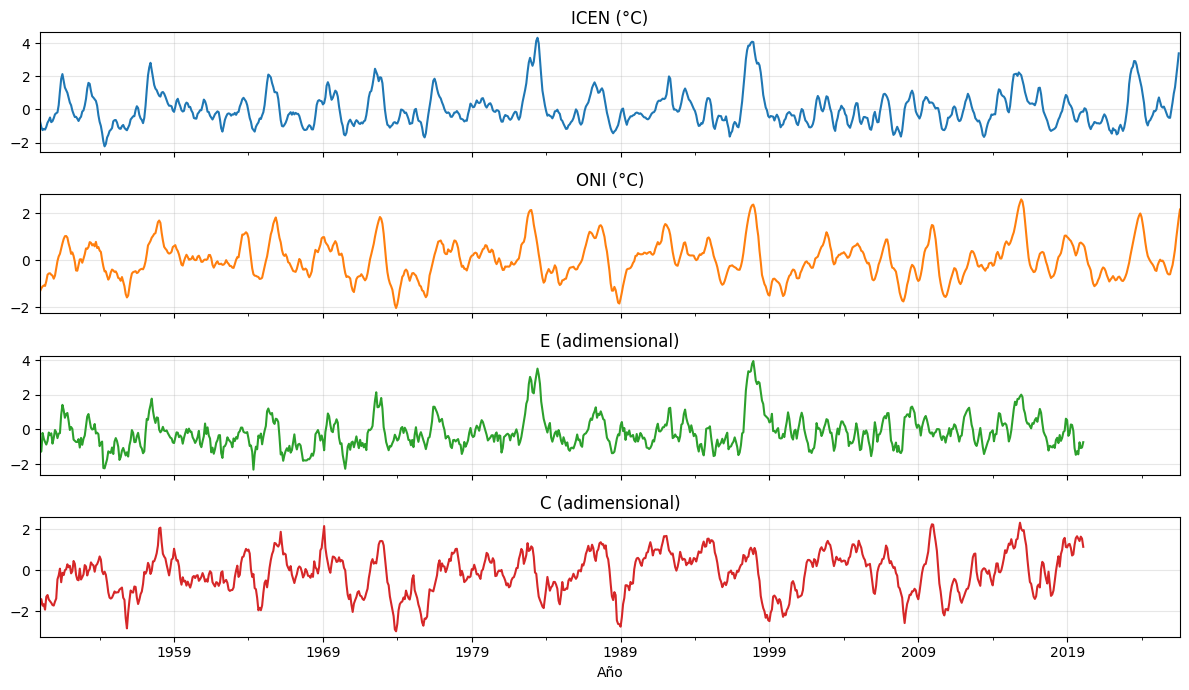

In [ ]:
indices = icen.merge(oni, on='fecha', how='outer').merge(ec, on='fecha', how='outer').sort_values('fecha')
indices.to_csv(os.path.join(SALIDA, '04_indices_enso_limpios.csv'), index=False)

base_mensual = (pp.reset_index().rename(columns={'pp_mm': 'pp_mm'})
                .merge(indices, on='fecha', how='left')
                .merge(tn.reset_index(), on='fecha', how='left')
                .merge(tx.reset_index(), on='fecha', how='left')
                .merge(pet.reset_index(), on='fecha', how='left'))
base_mensual['anio'] = base_mensual['fecha'].dt.year
base_mensual['mes'] = base_mensual['fecha'].dt.month
for c_flag in ['ICEN_interpolado', 'ONI_reconstruido']:
    base_mensual[c_flag] = base_mensual[c_flag].astype('boolean').fillna(False).astype(bool)

cols = ['pp_mm', 'ICEN', 'ONI', 'E', 'C', 'tmin_c', 'tmax_c', 'pet_mm']
resumen = pd.DataFrame({
    'primer_mes': [base_mensual.dropna(subset=[c]).fecha.min().strftime('%Y-%m') for c in cols],
    'ultimo_mes': [base_mensual.dropna(subset=[c]).fecha.max().strftime('%Y-%m') for c in cols],
    'nulos': [int(base_mensual[c].isna().sum()) for c in cols]}, index=cols)
print('Tabla mensual unida:', base_mensual.shape)
display(resumen)
base_mensual.to_csv(os.path.join(SALIDA, '07_base_mensual_pisco_enso.csv'), index=False)

indices.set_index('fecha').loc['1950':, ['ICEN', 'ONI', 'E', 'C']].plot(subplots=True, figsize=(12, 7), sharex=True,
    title=['ICEN (°C)', 'ONI (°C)', 'E (adimensional)', 'C (adimensional)'], legend=False)
plt.xlabel('Año'); plt.tight_layout(); plt.show()

**Decisiones de limpieza (qué se encontró y qué se hizo):**

| Archivo | Problema | Tratamiento |
|---|---|---|
| ICEN | 552 valores con coma decimal | Convertidos a punto |
| ICEN | Falta **nov-2015** (línea `21/11/2015` en su lugar) | Interpolación lineal (≈ 2.15 °C), marcada en `ICEN_interpolado` |
| ONI | 14 filas con `HIJO` en lugar de `SON` | Corregidas a `SON` |
| ONI | Comas decimales; 2 filas convertidas a fecha por Excel (`28.02.2009 1.31`, `29.10.2015 2.45`) | Comas a punto; las 2 filas se recuperaron como **OND 2009 y OND 2015** (verificar contra NOAA; marcadas en `ONI_reconstruido`) |
| E y C | 2512 valores con coma decimal | Convertidos a punto |

Tras la limpieza, **ICEN y ONI no tienen vacíos** en 1981-2025. Los vacíos que quedan son **ausencia de dato en la fuente y no se rellenan**: E y C terminan en feb-2020 (70 meses sin dato), la temperatura en 2020 y la evapotranspiración en 2016. Por eso los análisis con E y C llegan hasta 2020 (470 meses; 38 temporadas) y los resultados de esos dos índices no incluyen el evento de 2023.

### 6.2 Control de los valores reconstruidos (ICEN y ONI)

Los tres valores reconstruidos manualmente (ICEN nov-2015; ONI OND 2009 y OND 2015) quedan **marcados** en `ICEN_interpolado` y `ONI_reconstruido`. Todos caen en **noviembre**, fuera de la temporada húmeda (dic-may), de modo que **no entran en las medias por temporada** (secciones 8.2 a 8.4). Sí podrían influir, aunque poco, en el mapa de correlación de todo el año (7.6), en los rezagos de 8.1 y en el modelo mensual. La comprobación está en la sección **8.1b** (justo después de los rezagos), que rehace 8.1 **sin** esos meses.

**Contraste con NOAA (hecho el día de la entrega, con las tablas públicas del CPC; solo fragmentos accesibles).** Para OND 2009, la tabla ONI con ERSSTv5 da ≈ 1.4 y la de ERSSTv6 ≈ 1.3; el valor recuperado (1.31) es coherente con la **v6** y no con la v5. Para OND 2015 (2.45) no se pudo contrastar. **Acción pendiente del equipo:** abrir el TXT original, confirmar la versión del ONI descargada y escribirla en la sección de fuentes. Además, según el aviso 26-05 del NWS citado por el CPC, el índice que NOAA usa de forma **oficial** para monitoreo y predicción es el **RONI** (el ONI sigue publicándose); conviene aclararlo al presentar el ONI como «índice del Pacífico central».

In [ ]:
# 6.2 ¿Cambian los rezagos (8.1) si se excluyen los meses reconstruidos?
n_icen, n_oni = int(base_mensual['ICEN_interpolado'].sum()), int(base_mensual['ONI_reconstruido'].sum())
print(f'Meses con ICEN interpolado: {n_icen} | meses con ONI reconstruido: {n_oni}')
display(base_mensual.loc[base_mensual['ICEN_interpolado'] | base_mensual['ONI_reconstruido'],
                         ['fecha', 'ICEN', 'ONI', 'ICEN_interpolado', 'ONI_reconstruido']])
print('¿Alguno cae en la temporada húmeda (dic-may)?:',
      bool(base_mensual.loc[base_mensual['ICEN_interpolado'] | base_mensual['ONI_reconstruido'], 'mes'].isin([12, 1, 2, 3, 4, 5]).any()))

Meses con ICEN interpolado: 1 | meses con ONI reconstruido: 2


,fecha,ICEN,ONI,ICEN_interpolado,ONI_reconstruido
346,2009-11-01,0.420,1.31,False,True
418,2015-11-01,2.145,2.45,True,True


¿Alguno cae en la temporada húmeda (dic-may)?: False


## 7. Análisis exploratorio (AED)

### 7.1 Estadísticos descriptivos y distribución

,count,mean,std,min,25%,50%,75%,max,asimetría
pp_mm,540.0,33.756271,63.804622,1.115230,5.093490,12.949943,30.537952,508.384432,4.287168
tmin_c,480.0,17.582816,1.776174,14.225832,16.089755,17.360831,19.059332,21.893726,0.232937
tmax_c,480.0,27.556335,1.689202,23.843039,26.176898,27.241590,29.093671,31.310841,0.063156
pet_mm,432.0,127.439888,12.942204,97.022582,116.517268,128.628545,137.842896,152.885551,-0.202078
ICEN,540.0,0.036491,1.092080,-1.660000,-0.682500,-0.235000,0.482500,4.320000,1.456585
ONI,540.0,0.030204,0.828155,-1.850000,-0.520000,-0.080000,0.540000,2.590000,0.513454
E,470.0,0.001904,0.968918,-1.534980,-0.633132,-0.183122,0.414834,3.946380,1.390125
C,470.0,0.022922,1.047009,-2.746120,-0.735489,0.182376,0.862482,2.313940,-0.377918


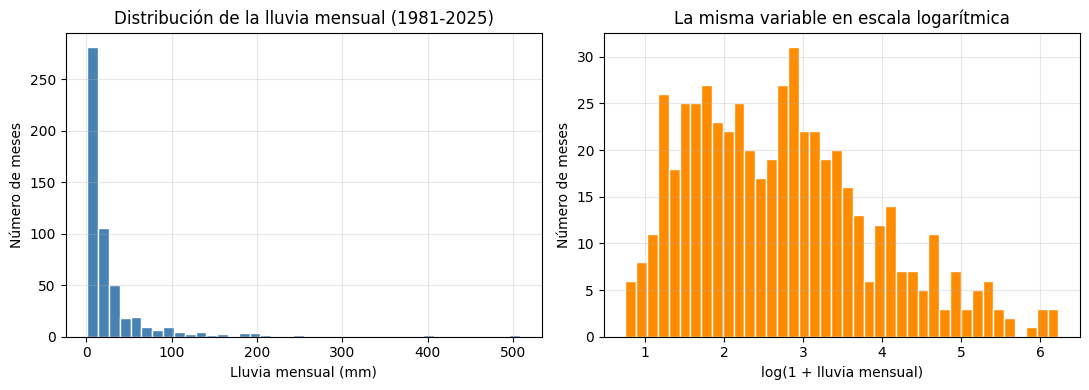

In [ ]:
vars_ = ['pp_mm', 'tmin_c', 'tmax_c', 'pet_mm', 'ICEN', 'ONI', 'E', 'C']
desc = base_mensual[vars_].describe().T
desc['asimetría'] = base_mensual[vars_].skew()
display(desc)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].hist(base_mensual['pp_mm'], bins=40, color='steelblue', edgecolor='white')
axs[0].set(xlabel='Lluvia mensual (mm)', ylabel='Número de meses', title='Distribución de la lluvia mensual (1981-2025)')
axs[1].hist(np.log1p(base_mensual['pp_mm']), bins=40, color='darkorange', edgecolor='white')
axs[1].set(xlabel='log(1 + lluvia mensual)', ylabel='Número de meses', title='La misma variable en escala logarítmica')
plt.tight_layout(); plt.show()

**Interpretación.** La lluvia mensual es **muy asimétrica** (asimetría 4.3): la mediana es 12.9 mm, pero la media es 33.8 mm y el máximo llega a 508 mm. Unos pocos meses extremos jalan el promedio hacia arriba. Por eso se usa la escala logarítmica para visualizar y la correlación de **Spearman** (no depende de la forma de la distribución) en lugar de Pearson.

### 7.2 Estacionalidad: ¿en qué meses llueve más?

,promedio_mm,mediana_mm,desv_mm,maximo_mm,n
Ene,44.161857,27.800946,63.234195,387.861041,45
Feb,93.488456,57.216696,88.437544,473.322499,45
Mar,118.204018,85.569723,114.255932,508.384432,45
Abr,60.273373,37.199851,78.283651,400.592624,45
May,20.882001,12.368426,38.866634,267.719685,45
Jun,7.436663,5.846385,10.445718,73.713911,45
Jul,3.676143,3.223169,1.730859,8.200837,45
Ago,3.877572,3.508686,1.700864,9.326459,45
Set,4.582167,3.945607,2.731431,12.423624,45
Oct,11.997200,11.289580,6.034613,22.750938,45


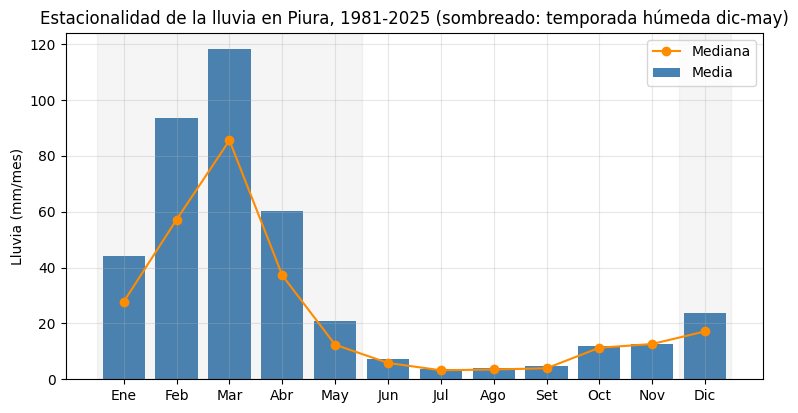

In [ ]:
meses = {1: 'Ene', 2: 'Feb', 3: 'Mar', 4: 'Abr', 5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Ago', 9: 'Set', 10: 'Oct', 11: 'Nov', 12: 'Dic'}
climatologia_mensual = base_mensual.groupby('mes')['pp_mm'].agg(promedio_mm='mean', mediana_mm='median', desv_mm='std', maximo_mm='max', n='count')
climatologia_mensual.index = [meses[m] for m in climatologia_mensual.index]
display(climatologia_mensual)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(climatologia_mensual.index, climatologia_mensual['promedio_mm'], color='steelblue', label='Media')
ax.plot(climatologia_mensual.index, climatologia_mensual['mediana_mm'], 'o-', color='darkorange', label='Mediana')
ax.axvspan(-0.5, 4.5, color='grey', alpha=0.08); ax.axvspan(10.5, 11.5, color='grey', alpha=0.08)
ax.set(ylabel='Lluvia (mm/mes)', title='Estacionalidad de la lluvia en Piura, 1981-2025 (sombreado: temporada húmeda dic-may)')
ax.legend(); plt.show()
climatologia_mensual.to_csv(os.path.join(SALIDA, 'estacionalidad_mensual_lluvia.csv'))

**Interpretación.** Llueve sobre todo de **enero a abril**, con máximo en **marzo** (media 118 mm, mediana 86 mm); diciembre y mayo son meses de transición (≈ 24 y 21 mm). De **junio a noviembre** la lluvia es baja (mediana ≤ 13 mm/mes, ≈ 3.5 mm en julio y agosto). La temporada **dic-may** concentra ≈ **89 %** de la lluvia anual media, lo que justifica definirla como temporada húmeda. En enero-mayo la desviación estándar es mayor que la media (en marzo 114 vs 118 mm): la lluvia varía mucho de un año a otro, con extremos de hasta 508 mm.

### 7.3 Valores atípicos (outliers)

Se detectan con la regla del rango intercuartílico (IQR) **por mes calendario**, porque la lluvia de marzo no es comparable con la de agosto. **Criterio de manejo:** los extremos **no se eliminan**, porque son justamente el fenómeno que se estudia (El Niño); se revisan y se asocian a eventos.

Meses marcados como outlier: 32 de 540

Outliers por año (número de meses):
anio
1983    5
1998    5
1997    3
2023    3
2017    3
2011    2
1999    2
1987    1
dtype: int64

Los 8 meses más lluviosos:


,pp_mm,ICEN,ONI,E,C
fecha,,,,,
2017-03-01,508.384432,1.31,0.27,1.18567,-0.836942
1998-03-01,496.434475,2.76,1.40,2.61549,0.437410
1998-02-01,473.322499,3.03,1.91,2.81411,0.905601
1983-03-01,405.402359,2.87,1.52,2.08573,0.654867
1983-04-01,400.592624,3.48,1.23,2.66901,-0.110497
1998-01-01,387.861041,3.49,2.22,3.42134,1.085750
2023-04-01,377.639675,2.11,0.19,NaN,NaN
2023-03-01,289.952330,1.53,-0.11,NaN,NaN


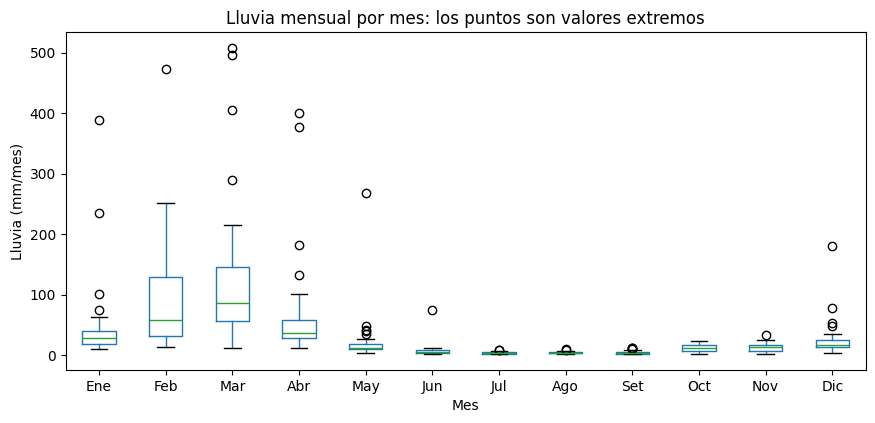

In [ ]:
def es_outlier(g):
    q1, q3 = g.quantile(0.25), g.quantile(0.75)
    return g > q3 + 1.5 * (q3 - q1)

base_mensual['outlier'] = base_mensual.groupby('mes')['pp_mm'].transform(es_outlier)
print('Meses marcados como outlier:', int(base_mensual['outlier'].sum()), 'de', len(base_mensual))
print('\nOutliers por año (número de meses):')
print(base_mensual[base_mensual['outlier']].groupby('anio').size().sort_values(ascending=False).head(8))
print('\nLos 8 meses más lluviosos:')
display(base_mensual.nlargest(8, 'pp_mm')[['fecha', 'pp_mm', 'ICEN', 'ONI', 'E', 'C']].set_index('fecha'))

ax = base_mensual.boxplot(column='pp_mm', by='mes', figsize=(10, 4.5), grid=False)
ax.set_xticklabels(list(meses.values())); ax.set(xlabel='Mes', ylabel='Lluvia (mm/mes)', title='Lluvia mensual por mes: los puntos son valores extremos')
plt.suptitle(''); plt.show()

**Interpretación.** Se marcan **32 de 540 meses (6 %)** como atípicos y casi todos caen en años de El Niño: **1983 y 1998 (5 meses cada uno)**, y 1997, 2017 y 2023 (3 cada uno). No son errores de medición sino el fenómeno de estudio, por eso **se conservan**. Un dato clave: el mes más lluvioso, **marzo de 2017 (508 mm)**, ocurrió con un ICEN de solo 1.31 y un ONI de 0.27, y **abril de 2023 (378 mm)** con ONI de 0.19; en cambio, en 1983 y 1998 el ICEN pasó de 2.8 y el ONI de 1.2. Es decir, **el ONI casi no detecta los eventos costeros**, lo que da pie a la hipótesis H1. También hay atípicos en años sin gran evento (1999, 2011), así que no toda la lluvia extrema viene de El Niño.

### 7.4 Serie de tiempo y eventos El Niño

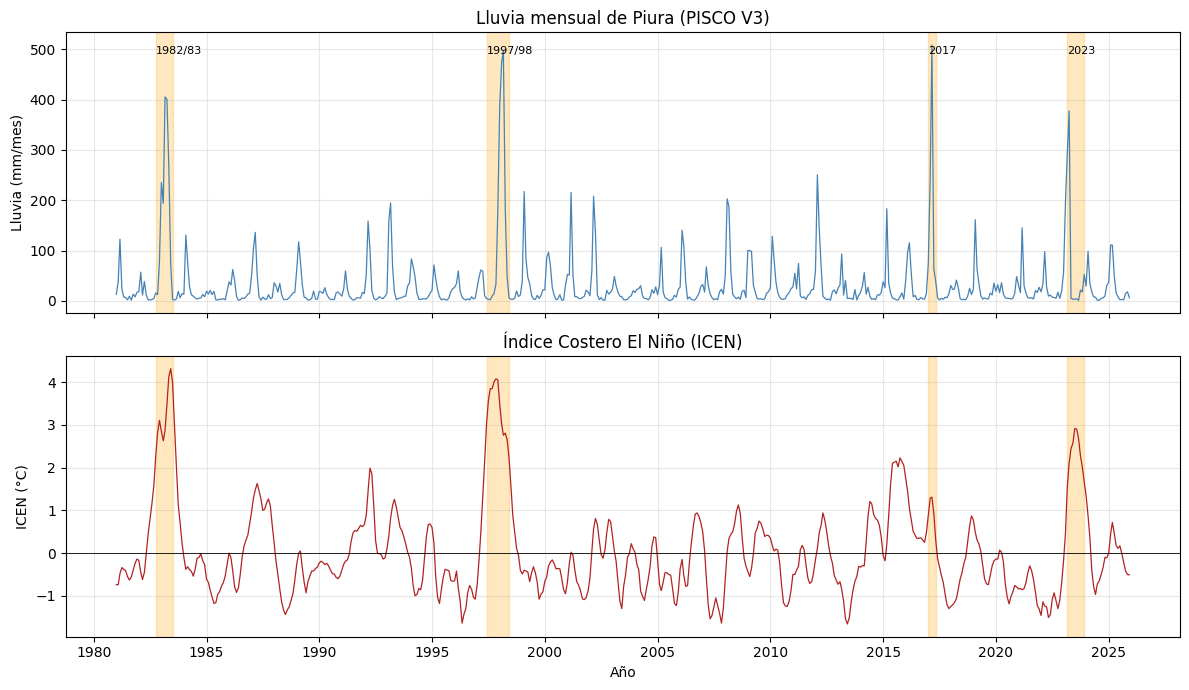

In [ ]:
eventos = {'1982/83': ('1982-10', '1983-07'), '1997/98': ('1997-06', '1998-06'),
           '2017': ('2017-01', '2017-05'), '2023': ('2023-03', '2023-12')}
fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axs[0].plot(base_mensual['fecha'], base_mensual['pp_mm'], color='steelblue', lw=0.9)
axs[0].set(ylabel='Lluvia (mm/mes)', title='Lluvia mensual de Piura (PISCO V3)')
axs[1].plot(base_mensual['fecha'], base_mensual['ICEN'], color='firebrick', lw=0.9)
axs[1].axhline(0, color='k', lw=0.6)
axs[1].set(ylabel='ICEN (°C)', xlabel='Año', title='Índice Costero El Niño (ICEN)')
for a in axs:
    for nom, (ini, fin) in eventos.items():
        a.axvspan(pd.Timestamp(ini), pd.Timestamp(fin), color='orange', alpha=0.25)
for nom, (ini, fin) in eventos.items():
    axs[0].text(pd.Timestamp(ini), axs[0].get_ylim()[1] * 0.92, nom, fontsize=8)
plt.tight_layout(); plt.show()

**Interpretación.** Los picos de lluvia coinciden con los eventos marcados. Los de **1982/83 y 1997/98** fueron largos y con ICEN por encima de 3 °C; los de **2017 y 2023** fueron más cortos y de ICEN moderado (≈ 1 a 2 °C), pero con meses de lluvia igual de intensos (508 y 378 mm). La cantidad de lluvia **no es proporcional al valor del índice**, de modo que la magnitud del ICEN por sí sola no basta para predecirla.

### 7.5 Temporada húmeda: lluvia total y lluvia extrema

Una **temporada húmeda** va de diciembre del año anterior a mayo (se nombra por el año en que termina). Solo se usan temporadas con los 6 meses completos (1982-2025). La **lluvia extrema** se mide como número de días con lluvia sobre el **percentil 95 de los días de temporada húmeda** (serie diaria).

Temporadas completas: 44 ( 1982 - 2025 )
Umbral de día extremo (percentil 95, dic-may): 8.94 mm/día


,lluvia_mm,ICEN,ONI,E,C,dias_extremos
temporada,,,,,,
1998,1765.976058,3.135000,1.555000,3.040847,0.419472,74
1983,1581.718412,3.178333,1.645000,2.647372,0.603700,74
2023,948.411796,0.948333,-0.173333,NaN,NaN,35
2017,946.499636,0.865000,0.095000,0.735876,-0.520771,36
2012,558.795905,0.260000,-0.526667,0.619148,-1.181537,18
2008,523.968953,-0.101667,-1.393333,0.315564,-1.843332,16
1993,468.631091,0.598333,0.396667,0.262665,0.602080,16
2002,440.517102,0.101667,0.026667,-0.384110,0.432491,13


,count,mean,std,min,25%,50%,75%,max
lluvia_mm,44.0,364.206691,341.998525,94.084226,180.488713,284.678861,366.860953,1765.976058
ICEN,44.0,0.053977,0.915816,-1.320000,-0.420833,-0.220000,0.354167,3.178333
ONI,44.0,0.043750,0.805742,-1.393333,-0.573333,0.057500,0.492500,1.778333
E,38.0,0.050738,0.830349,-0.845100,-0.508447,-0.117748,0.302339,3.040847
C,38.0,0.013260,1.035526,-1.996878,-0.687131,0.407461,0.830793,1.526605
dias_extremos,44.0,9.181818,16.413654,0.000000,1.000000,3.000000,8.500000,74.000000


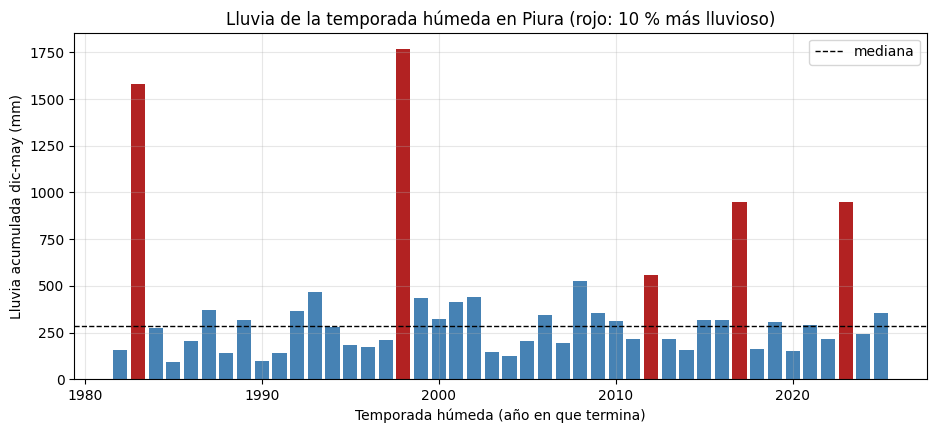

In [ ]:
def anio_temporada(idx):
    return idx.year + (idx.month == 12)      # diciembre pertenece a la temporada del año siguiente

hum = base_mensual[base_mensual['mes'].isin([12, 1, 2, 3, 4, 5])].copy()
hum['temp'] = anio_temporada(pd.DatetimeIndex(hum['fecha']))
validas = hum.groupby('temp')['pp_mm'].count().loc[lambda s: s == 6].index    # descarta 1981 y 2026 incompletas

def media_completa(g):
    return g.mean() if g.count() == 6 else np.nan

temporadas = pd.DataFrame({'lluvia_mm': hum.groupby('temp')['pp_mm'].sum()})
for c in ['ICEN', 'ONI', 'E', 'C']:
    temporadas[c] = hum.groupby('temp')[c].apply(media_completa)
temporadas = temporadas.loc[validas]

dd = pp_d[pp_d.index.month.isin([12, 1, 2, 3, 4, 5])].copy()
umbral_extremo = dd['pp_mm'].quantile(0.95)
dd['extremo'] = dd['pp_mm'] > umbral_extremo
dd['temp'] = anio_temporada(dd.index)
temporadas['dias_extremos'] = dd.groupby('temp')['extremo'].sum().reindex(temporadas.index)
temporadas.index.name = 'temporada'

print('Temporadas completas:', len(temporadas), '(', temporadas.index.min(), '-', temporadas.index.max(), ')')
print('Umbral de día extremo (percentil 95, dic-may): %.2f mm/día' % umbral_extremo)
display(temporadas.sort_values('lluvia_mm', ascending=False).head(8))
display(temporadas.describe().T)
temporadas.to_csv(os.path.join(SALIDA, '06_lluvia_temporada_humeda.csv'))

fig, ax = plt.subplots(figsize=(11, 4.5))
colores = np.where(temporadas['lluvia_mm'] > temporadas['lluvia_mm'].quantile(0.9), 'firebrick', 'steelblue')
ax.bar(temporadas.index, temporadas['lluvia_mm'], color=colores)
ax.axhline(temporadas['lluvia_mm'].median(), color='k', ls='--', lw=1, label='mediana')
ax.set(xlabel='Temporada húmeda (año en que termina)', ylabel='Lluvia acumulada dic-may (mm)',
       title='Lluvia de la temporada húmeda en Piura (rojo: 10 % más lluvioso)')
ax.legend(); plt.show()

**Interpretación.** La temporada húmeda típica es de **285 mm** (mediana), pero la media es 364 mm porque dos temporadas se disparan: **1998 (1766 mm)** y **1983 (1582 mm)**, seguidas por **2023 (948 mm)** y **2017 (946 mm)**. Los días de lluvia extrema (> 8.9 mm/día) se concentran todavía más: **74 días en 1983 y 74 en 1998**, frente a una mediana de 3 por temporada; esas dos temporadas suman ≈ **37 %** de todos los días extremos de 44 años. La lluvia de Piura está dominada por pocos eventos.

### 7.6 Correlaciones entre variables

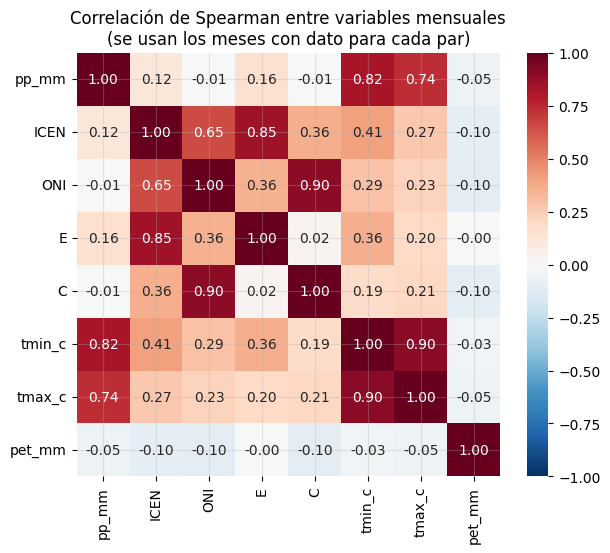

In [ ]:
cols = ['pp_mm', 'ICEN', 'ONI', 'E', 'C', 'tmin_c', 'tmax_c', 'pet_mm']
plt.figure(figsize=(7, 5.5))
sns.heatmap(base_mensual[cols].corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True)
plt.title('Correlación de Spearman entre variables mensuales\n(se usan los meses con dato para cada par)')
plt.show()

**Interpretación.** Con todos los meses del año la lluvia casi no se relaciona con los índices (ICEN 0.12, E 0.16, ONI y C ≈ 0), porque la estacionalidad domina la serie y los índices solo importan en la temporada húmeda; por eso la sección 8 trabaja con la temporada. La alta correlación con la temperatura (mínima 0.82, máxima 0.74) refleja sobre todo que **la lluvia y el calor coinciden en la misma época del año**, no una relación causal. La evapotranspiración potencial no se relaciona con la lluvia (−0.05).

## 8. Validación de hipótesis

### 8.1 H1: ¿qué índice se relaciona mejor con la lluvia? — rezagos
Se correlaciona la lluvia de cada mes de **temporada húmeda** con el índice de *k* meses antes (k = 0 a 6). Se usa **Spearman** porque la lluvia es muy asimétrica.

,ICEN,ONI,E,C
rezago_meses,,,,
0,0.315894,0.066689,0.386959,-0.045556
1,0.257831,0.042350,0.287439,-0.045037
2,0.136884,0.024205,0.224336,-0.035799
3,0.066165,0.009128,0.158129,-0.023388
4,0.039623,-0.005418,0.141544,-0.019656
5,0.071072,-0.001071,0.120615,-0.018448
6,0.104367,-0.000500,0.137297,-0.037755


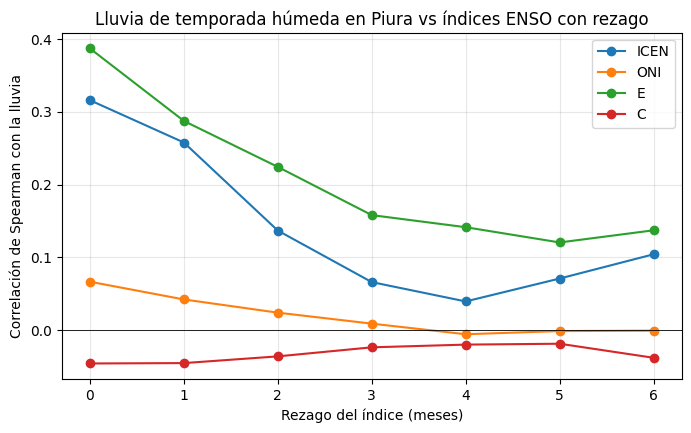

In [ ]:
en_temporada = base_mensual['mes'].isin([12, 1, 2, 3, 4, 5])
rez = {}
for ind in ['ICEN', 'ONI', 'E', 'C']:
    rez[ind] = [base_mensual.loc[en_temporada, 'pp_mm'].corr(base_mensual[ind].shift(k)[en_temporada], method='spearman') for k in range(7)]
correlaciones_rezagos = pd.DataFrame(rez, index=range(7)); correlaciones_rezagos.index.name = 'rezago_meses'
display(correlaciones_rezagos)
correlaciones_rezagos.to_csv(os.path.join(SALIDA, '09_correlaciones_rezagos.csv'))

plt.figure(figsize=(8, 4.5))
for c in correlaciones_rezagos.columns:
    plt.plot(correlaciones_rezagos.index, correlaciones_rezagos[c], 'o-', label=c)
plt.axhline(0, color='k', lw=0.6)
plt.xlabel('Rezago del índice (meses)'); plt.ylabel('Correlación de Spearman con la lluvia')
plt.title('Lluvia de temporada húmeda en Piura vs índices ENSO con rezago')
plt.legend(); plt.show()

### 8.2 H1 por temporada (lluvia total y días extremos)

,n_temporadas,Spearman vs lluvia total,Spearman vs días extremos
índice,,,
ICEN,44,0.503735,0.622344
ONI,44,0.008598,0.135203
E,38,0.754897,0.753745
C,38,-0.138855,-0.008479


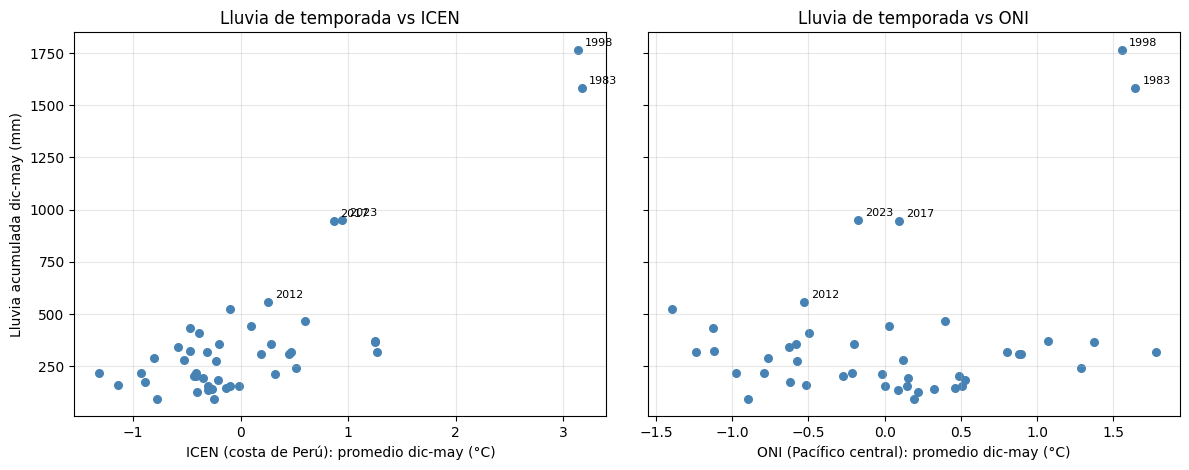

In [ ]:
filas = []
for ind in ['ICEN', 'ONI', 'E', 'C']:
    d = temporadas[[ind, 'lluvia_mm', 'dias_extremos']].dropna()
    filas.append({'índice': ind, 'n_temporadas': len(d),
                  'Spearman vs lluvia total': d[ind].corr(d['lluvia_mm'], method='spearman'),
                  'Spearman vs días extremos': d[ind].corr(d['dias_extremos'], method='spearman')})
tabla_h1 = pd.DataFrame(filas).set_index('índice')
display(tabla_h1)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for a, ind, nom in zip(axs, ['ICEN', 'ONI'], ['ICEN (costa de Perú)', 'ONI (Pacífico central)']):
    d = temporadas[[ind, 'lluvia_mm']].dropna()
    a.scatter(d[ind], d['lluvia_mm'], s=30, color='steelblue')
    for y in d['lluvia_mm'].nlargest(5).index:
        a.annotate(str(y), (d.loc[y, ind], d.loc[y, 'lluvia_mm']), textcoords='offset points', xytext=(5, 3), fontsize=8)
    a.set(xlabel=f'{nom}: promedio dic-may (°C)', title=f'Lluvia de temporada vs {ind}')
axs[0].set_ylabel('Lluvia acumulada dic-may (mm)')
plt.tight_layout(); plt.show()

**Interpretación (H1).** En los meses de temporada húmeda, la mayor relación aparece **sin rezago** y decae al aumentar el rezago: **E 0.39** y **ICEN 0.32**, frente a **ONI 0.07** y **C −0.05**. Por temporada la diferencia es mayor: con la lluvia total, **E 0.75** y **ICEN 0.50** contra **ONI 0.01** y **C −0.14**; con los días extremos, E 0.75 e ICEN 0.62 contra ONI 0.14 y C −0.01. En el gráfico se ve por qué: 2017 y 2023 tienen ~950 mm con ONI ≈ 0 (en 2023, negativo) pero ICEN ≈ 0.9. **H1 se cumple de forma preliminar**: la lluvia de Piura sigue a los índices de la costa (ICEN, E) y no a los del Pacífico central (ONI, C). Precauciones: es asociación y no causalidad, E y C no incluyen 2023, y hay 38 a 44 temporadas.

#### 8.1b Control: ¿dependen los rezagos de los meses reconstruidos?
Se rehacen las correlaciones con rezago de 8.1 **sin** los meses reconstruidos de ICEN y ONI (sección 6.2).

In [ ]:
# 8.1b Rezagos sin los meses reconstruidos
chk = base_mensual.copy()
chk.loc[chk['ICEN_interpolado'], 'ICEN'] = np.nan
chk.loc[chk['ONI_reconstruido'], 'ONI'] = np.nan
en_t = chk['mes'].isin([12, 1, 2, 3, 4, 5])
rez_chk = pd.DataFrame({ind: [chk.loc[en_t, 'pp_mm'].corr(chk[ind].shift(k)[en_t], method='spearman') for k in range(7)]
                        for ind in ['ICEN', 'ONI']})
dif_max = (rez_chk - correlaciones_rezagos[['ICEN', 'ONI']]).abs().max().max()
print(f'Máxima diferencia en las correlaciones con rezago al excluir esos meses: {dif_max:.3f}')
print('Conclusión:', 'los resultados de 8.1 no dependen de los valores reconstruidos.' if dif_max < 0.02
      else 'hay diferencias apreciables: revisar los valores originales antes de presentar 8.1.')

Máxima diferencia en las correlaciones con rezago al excluir esos meses: 0.015
Conclusión: los resultados de 8.1 no dependen de los valores reconstruidos.


### 8.3 H2: ¿cambió la relación entre periodos? (E y C terminan en 2020)

**Periodos:** empiezan en **1982** porque la temporada húmeda 1981 necesitaría diciembre de 1980 y la serie PISCO inicia en enero de 1981; terminan en **2025** porque PISCO V3 llega hasta diciembre de 2025 y esa temporada está completa. Esto reemplaza el esquema 1981-1999 / 2000-2024 de la propuesta inicial.

n            Spearman          
periodo 1982-1999 2000-2025 1982-1999 2000-2025
índice                                         
C            18.0      20.0  0.137255 -0.369925
E            18.0      20.0  0.727554  0.560902
ICEN         18.0      26.0  0.556244  0.435897
ONI          18.0      26.0  0.380805 -0.262222

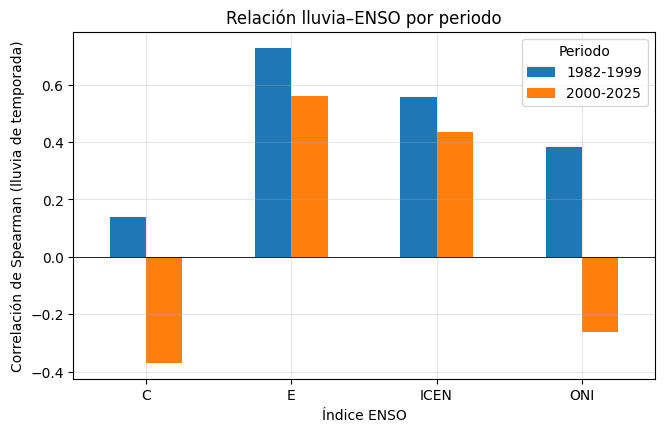

In [ ]:
filas = []
for ind in ['ICEN', 'ONI', 'E', 'C']:
    for nom, (a, b) in {'1982-1999': (1982, 1999), '2000-2025': (2000, 2025)}.items():
        d = temporadas.loc[a:b, [ind, 'lluvia_mm']].dropna()
        filas.append({'índice': ind, 'periodo': nom, 'n': len(d), 'Spearman': d[ind].corr(d['lluvia_mm'], method='spearman')})
comparacion_periodos = pd.DataFrame(filas)
display(comparacion_periodos.pivot(index='índice', columns='periodo', values=['n', 'Spearman']))
comparacion_periodos.to_csv(os.path.join(SALIDA, '08_correlacion_por_periodo.csv'), index=False)

pv = comparacion_periodos.pivot(index='índice', columns='periodo', values='Spearman')
pv.plot(kind='bar', figsize=(7.5, 4.5), rot=0)
plt.axhline(0, color='k', lw=0.6)
plt.ylabel('Correlación de Spearman (lluvia de temporada)'); plt.xlabel('Índice ENSO')
plt.title('Relación lluvia–ENSO por periodo'); plt.legend(title='Periodo'); plt.show()

### 8.4 Prueba de robustez: ¿dependen los resultados de 1983 y 1998?

In [ ]:
sin_extremos = temporadas.drop(index=[1983, 1998])
filas = []
for ind in ['ICEN', 'ONI', 'E', 'C']:
    d_todo = temporadas[[ind, 'lluvia_mm']].dropna()
    d_sin = sin_extremos[[ind, 'lluvia_mm']].dropna()
    filas.append({'índice': ind,
                  'Spearman con todas': d_todo[ind].corr(d_todo['lluvia_mm'], method='spearman'),
                  'Spearman sin 1983 y 1998': d_sin[ind].corr(d_sin['lluvia_mm'], method='spearman'),
                  'n sin ellas': len(d_sin)})
robustez = pd.DataFrame(filas).set_index('índice')
display(robustez)

,Spearman con todas,Spearman sin 1983 y 1998,n sin ellas
índice,,,
ICEN,0.503735,0.429544,42
ONI,0.008598,-0.134754,42
E,0.754897,0.711712,36
C,-0.138855,-0.202574,36


**Interpretación (H2).** Entre 1982-1999 y 2000-2025 la relación **cambia, sobre todo en los índices del Pacífico central**: ONI pasa de **0.38 a −0.26** y C de 0.14 a −0.37, mientras que los índices costeros **se debilitan pero siguen positivos** (ICEN 0.56 → 0.44; E 0.73 → 0.56). Es coherente con que en el segundo periodo hubo eventos costeros (2017 y 2023) que el ONI no registró. La prueba de robustez muestra que **no depende solo de 1983 y 1998**: sin esas dos temporadas, E sigue en 0.71 e ICEN en 0.43. **Pero con 18 a 26 temporadas por periodo, estas diferencias no son concluyentes**: H2 queda como *indicio* y no como resultado confirmado. Para afirmarla falta calcular intervalos de confianza (por ejemplo con remuestreo).

### 8.3b H2 con muestra común e intervalos de confianza

Dos problemas de la comparación anterior: (1) ICEN y ONI llegan a 2025 pero E y C solo a 2020, de modo que **no se comparan sobre las mismas temporadas**; (2) con 18 a 26 temporadas por periodo, una diferencia de correlación puede ser azar. Aquí se usa la **misma muestra para los cuatro índices** (temporadas con los cuatro datos: 1982-2019) y se estima la incertidumbre con **remuestreo bootstrap** (2000 repeticiones, percentiles 2.5 y 97.5). Periodos: 1982-1999 y 2000-2019 (2019 es la última temporada completa con E y C: la temporada 2020 necesitaría datos hasta may-2020 y E y C terminan en feb-2020).

Muestra común: 38 temporadas (1982-2019) | periodo 1: 18 | periodo 2: 20


,rho_1982_1999,IC95_inf_1,IC95_sup_1,rho_2000_2019,IC95_inf_2,IC95_sup_2,cambio,IC95_cambio_inf,IC95_cambio_sup,el_IC_del_cambio_excluye_0
índice,,,,,,,,,,
ICEN,0.56,-0.01,0.86,0.38,-0.04,0.69,-0.18,-0.71,0.46,False
ONI,0.38,-0.22,0.78,-0.34,-0.60,0.07,-0.72,-1.21,-0.04,True
E,0.73,0.29,0.91,0.56,0.14,0.84,-0.17,-0.65,0.35,False
C,0.14,-0.33,0.56,-0.37,-0.64,0.04,-0.51,-1.01,0.13,False


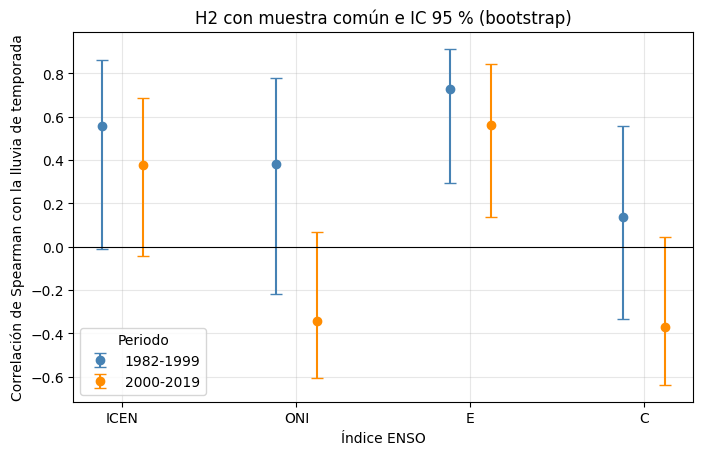

Índices cuyo cambio entre periodos tiene IC 95 % que NO incluye 0: ['ONI']
Si ningún IC excluye 0, H2 sigue siendo un indicio y no un resultado confirmado; la ausencia de evidencia no demuestra estabilidad.


In [ ]:
# 8.3b Muestra común + bootstrap de la diferencia de correlación entre periodos
indices_h2 = ['ICEN', 'ONI', 'E', 'C']
comun_h2 = temporadas[indices_h2 + ['lluvia_mm']].dropna()
per1, per2 = (1982, 1999), (2000, 2019)
d1_all, d2_all = comun_h2.loc[per1[0]:per1[1]], comun_h2.loc[per2[0]:per2[1]]
print(f'Muestra común: {len(comun_h2)} temporadas ({comun_h2.index.min()}-{comun_h2.index.max()}) | '
      f'periodo 1: {len(d1_all)} | periodo 2: {len(d2_all)}')

rng = np.random.default_rng(42)
N_BOOT = 2000
filas = []
for ind in indices_h2:
    r1 = d1_all[ind].corr(d1_all['lluvia_mm'], method='spearman')
    r2 = d2_all[ind].corr(d2_all['lluvia_mm'], method='spearman')
    b1, b2 = [], []
    for _ in range(N_BOOT):
        s1 = d1_all.iloc[rng.integers(0, len(d1_all), len(d1_all))]
        s2 = d2_all.iloc[rng.integers(0, len(d2_all), len(d2_all))]
        b1.append(s1[ind].corr(s1['lluvia_mm'], method='spearman'))
        b2.append(s2[ind].corr(s2['lluvia_mm'], method='spearman'))
    b1, b2 = np.array(b1), np.array(b2)
    dif = b2 - b1
    filas.append({'índice': ind, 'rho_1982_1999': r1, 'IC95_inf_1': np.nanpercentile(b1, 2.5), 'IC95_sup_1': np.nanpercentile(b1, 97.5),
                  'rho_2000_2019': r2, 'IC95_inf_2': np.nanpercentile(b2, 2.5), 'IC95_sup_2': np.nanpercentile(b2, 97.5),
                  'cambio': r2 - r1, 'IC95_cambio_inf': np.nanpercentile(dif, 2.5), 'IC95_cambio_sup': np.nanpercentile(dif, 97.5)})
tabla_h2b = pd.DataFrame(filas).set_index('índice')
tabla_h2b['el_IC_del_cambio_excluye_0'] = (tabla_h2b['IC95_cambio_inf'] > 0) | (tabla_h2b['IC95_cambio_sup'] < 0)
display(tabla_h2b.round(2))
tabla_h2b.to_csv(os.path.join(SALIDA, '08b_h2_muestra_comun_bootstrap.csv'))

fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(len(tabla_h2b))
for off, col, etq, a, b, c in [(-0.12, 'steelblue', f'{per1[0]}-{per1[1]}', 'rho_1982_1999', 'IC95_inf_1', 'IC95_sup_1'),
                               (0.12, 'darkorange', f'{per2[0]}-{per2[1]}', 'rho_2000_2019', 'IC95_inf_2', 'IC95_sup_2')]:
    ax.errorbar(x + off, tabla_h2b[a], yerr=[tabla_h2b[a] - tabla_h2b[b], tabla_h2b[c] - tabla_h2b[a]],
                fmt='o', color=col, capsize=4, label=etq)
ax.axhline(0, color='k', lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(tabla_h2b.index)
ax.set(ylabel='Correlación de Spearman con la lluvia de temporada', xlabel='Índice ENSO',
       title='H2 con muestra común e IC 95 % (bootstrap)')
ax.legend(title='Periodo'); plt.show()

sig = list(tabla_h2b.index[tabla_h2b['el_IC_del_cambio_excluye_0']])
print('Índices cuyo cambio entre periodos tiene IC 95 % que NO incluye 0:', sig if sig else 'ninguno')
print("Si ningún IC excluye 0, H2 sigue siendo un indicio y no un resultado confirmado; la ausencia de evidencia no demuestra estabilidad.")

### 8.5 Contraste con estaciones SENAMHI (si hay datos)

Estaciones usadas: 8 | meses comparables: 418 ( 1981-01 a 2015-10 )
Correlación PISCO (depto.) vs promedio de estaciones -> Pearson: 0.970 | Spearman: 0.942


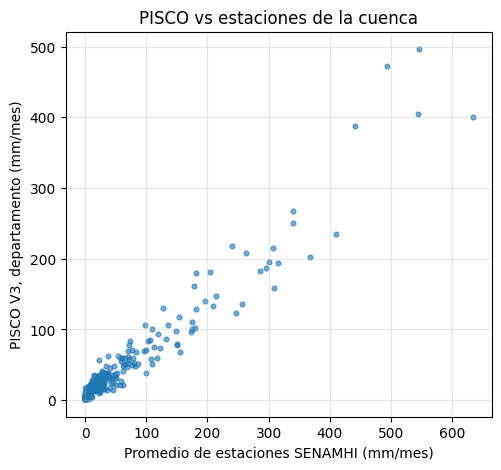

In [ ]:
if len(mensual_estaciones) > 0:
    sel = mensual_estaciones[mensual_estaciones['estacion'].isin(estaciones_cuenca['estacion'].unique())]
    prom_est = sel.groupby('fecha')['pp_mensual_mm'].mean().rename('pp_estaciones_mm')
    cmp = pp.join(prom_est, how='inner').dropna()
    print('Estaciones usadas:', sel['estacion'].nunique(), '| meses comparables:', len(cmp),
          '(', cmp.index.min().strftime('%Y-%m'), 'a', cmp.index.max().strftime('%Y-%m'), ')')
    print('Correlación PISCO (depto.) vs promedio de estaciones -> Pearson: %.3f | Spearman: %.3f' %
          (cmp['pp_mm'].corr(cmp['pp_estaciones_mm']), cmp['pp_mm'].corr(cmp['pp_estaciones_mm'], method='spearman')))
    plt.figure(figsize=(5.5, 5))
    plt.scatter(cmp['pp_estaciones_mm'], cmp['pp_mm'], s=12, alpha=0.6)
    plt.xlabel('Promedio de estaciones SENAMHI (mm/mes)'); plt.ylabel('PISCO V3, departamento (mm/mes)')
    plt.title('PISCO vs estaciones de la cuenca'); plt.show()
else:
    print('Sección omitida: no hay datos de estaciones.')

**Interpretación.** El promedio de las **8 estaciones SENAMHI** ubicadas dentro de la cuenca y PISCO V3 (promedio del departamento) coinciden con una correlación de **0.97** (Pearson) y **0.94** (Spearman) en **418 meses (1981-01 a 2015-10)**. Es una validación independiente razonable: PISCO reproduce bien el patrón mensual observado en tierra, aunque sea un promedio departamental. **Límites:** las estaciones terminan entre 2013 y 2015, así que esta validación **no cubre los eventos de 2017 y 2023**, y la correlación no mide sesgo en la magnitud de los extremos.

## 9. Eventos El Niño y anomalías respecto a la normal 1991-2020

Responde las preguntas del profesor: ¿en qué meses llueve más? (sección 7.2) · ¿cuánto llovió en los eventos? · ¿qué porcentaje por encima o por debajo de lo normal? · ¿cómo se compara con la normal climatológica?

Normal de la temporada húmeda (1992-2020): 365.7 mm


,temporada,lluvia_mm,normal_mm,anomalía_mm,anomalía_%,veces_la_normal,días_extremos
evento,,,,,,,
El Niño 1982/83,dic 1982 - may 1983,1581.718412,365.66549,1216.052922,332.558842,4.325588,74
El Niño 1997/98,dic 1997 - may 1998,1765.976058,365.66549,1400.310568,382.948516,4.829485,74
El Niño costero 2017,dic 2016 - may 2017,946.499636,365.66549,580.834146,158.843030,2.588430,36
El Niño costero 2023,dic 2022 - may 2023,948.411796,365.66549,582.746306,159.365956,2.593660,35


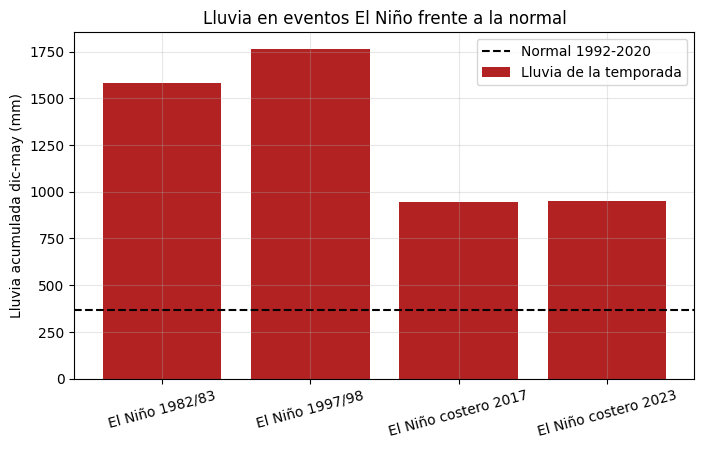

In [ ]:
# Normal mensual y de temporada, periodo de referencia 1991-2020
ref = base_mensual[base_mensual['anio'].between(1991, 2020)]
normal_mensual = ref.groupby('mes')['pp_mm'].mean().rename('normal_1991_2020_mm')
normal_temporada = temporadas.loc[1992:2020, 'lluvia_mm'].mean()     # temporadas completas dentro de 1991-2020
print('Normal de la temporada húmeda (1992-2020): %.1f mm' % normal_temporada)

anom = base_mensual[['fecha', 'anio', 'mes', 'pp_mm']].merge(normal_mensual, on='mes', how='left')
anom['anomalia_mm'] = anom['pp_mm'] - anom['normal_1991_2020_mm']
anom['anomalia_pct'] = 100 * anom['anomalia_mm'] / anom['normal_1991_2020_mm']
anom.to_csv(os.path.join(SALIDA, 'anomalias_mensuales_lluvia.csv'), index=False)

# Tabla por evento: lluvia de la temporada vs normal
ev = {'El Niño 1982/83': 1983, 'El Niño 1997/98': 1998, 'El Niño costero 2017': 2017, 'El Niño costero 2023': 2023}
filas = []
for nombre, t in ev.items():
    ll = temporadas.loc[t, 'lluvia_mm']
    filas.append({'evento': nombre, 'temporada': f'dic {t-1} - may {t}', 'lluvia_mm': ll,
                  'normal_mm': normal_temporada, 'anomalía_mm': ll - normal_temporada,
                  'anomalía_%': 100 * (ll - normal_temporada) / normal_temporada,
                  'veces_la_normal': ll / normal_temporada,
                  'días_extremos': temporadas.loc[t, 'dias_extremos']})
tabla_eventos = pd.DataFrame(filas).set_index('evento')
display(tabla_eventos)
tabla_eventos.to_csv(os.path.join(SALIDA, 'lluvia_eventos_vs_normal.csv'))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(tabla_eventos.index, tabla_eventos['lluvia_mm'], color='firebrick', label='Lluvia de la temporada')
ax.axhline(normal_temporada, color='k', ls='--', label='Normal 1992-2020')
ax.set(ylabel='Lluvia acumulada dic-may (mm)', title='Lluvia en eventos El Niño frente a la normal')
plt.xticks(rotation=15); ax.legend(); plt.show()

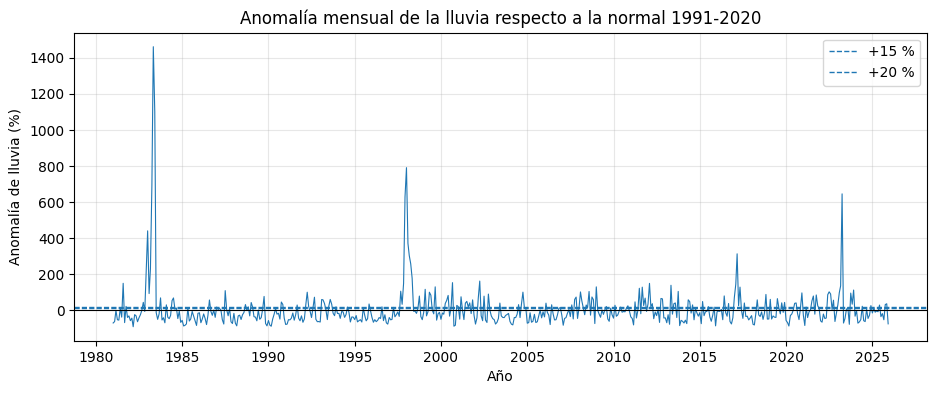

,meses,mediana_anomalia_pct,pct_meses_sobre_15,pct_meses_sobre_20
Temporadas sin evento,240,-32.329471,17.5,14.583333
Temporadas con evento,24,198.269022,87.5,87.500000


In [ ]:
# Serie mensual de anomalías y meses por encima de umbrales
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(anom['fecha'], anom['anomalia_pct'], lw=0.8)
for u in (15, 20):
    ax.axhline(u, ls='--', lw=1, label=f'+{u} %')
ax.axhline(0, color='k', lw=0.8)
ax.set(xlabel='Año', ylabel='Anomalía de lluvia (%)', title='Anomalía mensual de la lluvia respecto a la normal 1991-2020')
ax.legend(); plt.show()

mh = anom[anom['mes'].isin([12, 1, 2, 3, 4, 5])].copy()
mh['temp'] = anio_temporada(pd.DatetimeIndex(mh['fecha']))
mh = mh[mh['temp'].between(1982, 2025)]
mh['evento'] = mh['temp'].isin(ev.values())
res = mh.groupby('evento')['anomalia_pct'].agg(
    meses='count', mediana_anomalia_pct='median',
    pct_meses_sobre_15=lambda s: 100 * (s >= 15).mean(),
    pct_meses_sobre_20=lambda s: 100 * (s >= 20).mean())
res.index = ['Temporadas sin evento', 'Temporadas con evento']
display(res)

**Interpretación.** Frente a la normal de la temporada húmeda (366 mm): **1982/83 llovió 1582 mm (4.3 veces la normal, +333 %)** y **1997/98 1766 mm (4.8 veces, +383 %)**, con 74 días extremos cada una; **2017 y 2023 llovieron ≈ 947 mm (2.6 veces, +159 %)**, con 35 a 36 días extremos. En las temporadas con evento, **87.5 % de los meses superó +20 % de anomalía**, frente a **14.6 %** en las demás. Ojo: en las temporadas sin evento la anomalía mediana es **−32 %**, porque la normal (un promedio) está inflada por unas pocas temporadas extremas; una temporada típica queda por debajo de la normal. Conviene aclararlo al presentar, o usar la mediana como referencia.

**Nota sobre las etiquetas.** «2023» en estas tablas es **solo** la temporada húmeda dic 2022 – may 2023. El episodio de El Niño costero no se limita a esa temporada: la temporada dic 2023 – may 2024 se analiza por separado en la sección 9.1.

### 9.1 Temporada húmeda vs. episodio El Niño: el caso 2023 – 2024

En este cuaderno una **temporada húmeda** se nombra por el año en que termina (2023 = dic 2022 – may 2023; 2024 = dic 2023 – may 2024). Un **episodio de El Niño** no coincide con una temporada: puede empezar a mitad de una y seguir en la siguiente. Por eso la fila «2023» de la tabla de eventos describe **solo** dic 2022 – may 2023 y no debe presentarse como todo el episodio 2023 – 2024. Aquí se muestran por separado las temporadas 2022 a 2025 (las fechas oficiales del episodio deben tomarse de los comunicados del ENFEN).

,temporada_húmeda,lluvia_mm,dias_extremos,ICEN,ONI,normal_mm,anomalía_%,veces_la_normal
temporada,,,,,,,,
2022,dic 2021 - may 2022,215.92,0,-1.32,-0.79,365.67,-40.95,0.59
2023,dic 2022 - may 2023,948.41,35,0.95,-0.17,365.67,159.37,2.59
2024,dic 2023 - may 2024,243.36,3,0.52,1.29,365.67,-33.45,0.67
2025,dic 2024 - may 2025,355.40,8,0.28,-0.20,365.67,-2.81,0.97


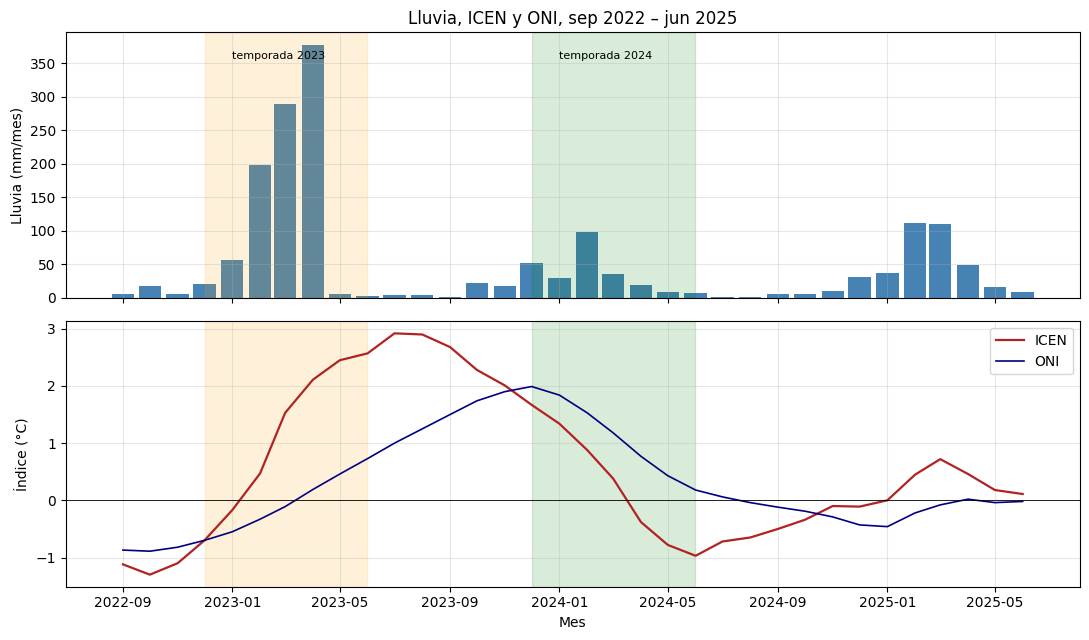

,meses,mediana_anomalia_pct,pct_meses_sobre_15,pct_meses_sobre_20
Temporadas sin evento,234,-32.2,17.5,14.5
Temporadas con evento (incluye 2024),30,132.3,73.3,73.3


Temporada 2023 (dic 2022 - may 2023): 948 mm = 2.59 veces la normal (+159 %), ICEN medio dic-may 0.95 °C.
Temporada 2024 (dic 2023 - may 2024): 243 mm = 0.67 veces la normal (-33 %), ICEN medio dic-may 0.52 °C.
Para el informe: nombrar siempre la temporada con sus meses (dic-may) y citar las fechas del episodio desde los comunicados ENFEN.


In [ ]:
# 9.1 Temporadas húmedas 2022-2025 frente a la normal 1992-2020 (temporada "2023" ≠ episodio completo)
tabla_2023 = temporadas.loc[2022:2025, ['lluvia_mm', 'dias_extremos', 'ICEN', 'ONI']].copy()
tabla_2023['normal_mm'] = normal_temporada
tabla_2023['anomalía_%'] = 100 * (tabla_2023['lluvia_mm'] - normal_temporada) / normal_temporada
tabla_2023['veces_la_normal'] = tabla_2023['lluvia_mm'] / normal_temporada
tabla_2023.insert(0, 'temporada_húmeda', [f'dic {t-1} - may {t}' for t in tabla_2023.index])
display(tabla_2023.round(2))
tabla_2023.to_csv(os.path.join(SALIDA, 'temporadas_2022_2025_vs_normal.csv'))

mm = base_mensual.set_index('fecha').loc['2022-09':'2025-06', ['pp_mm', 'ICEN', 'ONI']]
fig, axs = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
axs[0].bar(mm.index, mm['pp_mm'], width=25, color='steelblue')
axs[0].set(ylabel='Lluvia (mm/mes)', title='Lluvia, ICEN y ONI, sep 2022 – jun 2025')
axs[1].plot(mm.index, mm['ICEN'], color='firebrick', lw=1.6, label='ICEN')
axs[1].plot(mm.index, mm['ONI'], color='navy', lw=1.2, label='ONI')
axs[1].axhline(0, color='k', lw=0.6); axs[1].set(ylabel='Índice (°C)', xlabel='Mes'); axs[1].legend()
for a in axs:
    for t, col in [(2023, 'orange'), (2024, 'green')]:
        a.axvspan(pd.Timestamp(t - 1, 12, 1), pd.Timestamp(t, 5, 31), color=col, alpha=0.15)
axs[0].text(pd.Timestamp(2023, 1, 1), axs[0].get_ylim()[1] * 0.9, 'temporada 2023', fontsize=8)
axs[0].text(pd.Timestamp(2024, 1, 1), axs[0].get_ylim()[1] * 0.9, 'temporada 2024', fontsize=8)
plt.tight_layout(); plt.show()

# Sensibilidad: ¿cambia la comparación "con evento / sin evento" si la temporada 2024 se cuenta como evento?
ev_ext = dict(ev); ev_ext['El Niño 2023/24'] = 2024
mh2 = mh.copy()
mh2['evento'] = mh2['temp'].isin(ev_ext.values())
res2 = mh2.groupby('evento')['anomalia_pct'].agg(
    meses='count', mediana_anomalia_pct='median',
    pct_meses_sobre_15=lambda s: 100 * (s >= 15).mean(), pct_meses_sobre_20=lambda s: 100 * (s >= 20).mean())
res2.index = ['Temporadas sin evento', 'Temporadas con evento (incluye 2024)']
display(res2.round(1))

for t in (2023, 2024):
    f = tabla_2023.loc[t]
    print(f"Temporada {t} ({f['temporada_húmeda']}): {f['lluvia_mm']:.0f} mm = {f['veces_la_normal']:.2f} veces la normal "
          f"({f['anomalía_%']:+.0f} %), ICEN medio dic-may {f['ICEN']:.2f} °C.")
print("Para el informe: nombrar siempre la temporada con sus meses (dic-may) y citar las fechas del episodio desde los comunicados ENFEN.")

## 10. Modelo base (línea de referencia)

Primer modelo, **solo como referencia** para las siguientes entregas. Reglas: división **cronológica** 80/20 (no aleatoria), **misma muestra para todos los modelos**, y comparación contra una **línea base de climatología** (predecir siempre la lluvia normal del mes). Un modelo solo es útil si supera esa línea base.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

datos = base_mensual[['fecha', 'pp_mm', 'mes', 'ICEN', 'ONI', 'E', 'C']].dropna().sort_values('fecha').reset_index(drop=True)
corte = int(len(datos) * 0.80)
train, test = datos.iloc[:corte].copy(), datos.iloc[corte:].copy()
print('Muestra común:', datos['fecha'].min().strftime('%Y-%m'), 'a', datos['fecha'].max().strftime('%Y-%m'),
      '| entrenamiento:', len(train), '| prueba:', len(test), '(', test['fecha'].min().strftime('%Y-%m'), 'en adelante )')

normal_train = train.groupby('mes')['pp_mm'].mean()              # climatología solo con datos de entrenamiento
train['normal_mes'] = train['mes'].map(normal_train)
test['normal_mes'] = test['mes'].map(normal_train)

def evaluar(nombre, modelo, y_real, y_pred):
    return {'modelo': nombre, 'MAE_mm': mean_absolute_error(y_real, y_pred),
            'RMSE_mm': mean_squared_error(y_real, y_pred) ** 0.5, 'R2': r2_score(y_real, y_pred)}

resultados = [evaluar('Climatología (línea base)', '', test['pp_mm'], test['normal_mes'])]
for etiqueta, vars_ in [('ICEN', ['ICEN']), ('ONI', ['ONI']), ('E', ['E']), ('C', ['C']), ('Todos', ['ICEN', 'ONI', 'E', 'C'])]:
    X_tr, X_te = train[['normal_mes'] + vars_], test[['normal_mes'] + vars_]
    for nom, mod in [('Regresión lineal', LinearRegression()),
                     ('Random Forest', RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42))]:
        mod.fit(X_tr, train['pp_mm'])
        resultados.append(evaluar(f'{nom} + normal del mes + {etiqueta}', mod, test['pp_mm'], mod.predict(X_te)))

metricas_modelos = pd.DataFrame(resultados).sort_values('RMSE_mm').reset_index(drop=True)
display(metricas_modelos)
metricas_modelos.to_csv(os.path.join(SALIDA, '10_metricas_modelos.csv'), index=False)

Muestra común: 1981-01 a 2020-02 | entrenamiento: 376 | prueba: 94 ( 2012-05 en adelante )


,modelo,MAE_mm,RMSE_mm,R2
0,Random Forest + normal del mes + Todos,16.800618,41.030631,0.572380
1,Random Forest + normal del mes + E,16.019693,42.054042,0.550782
2,Random Forest + normal del mes + ICEN,16.659487,43.118867,0.527745
3,Regresión lineal + normal del mes + ICEN,29.194854,50.109517,0.362204
4,Regresión lineal + normal del mes + C,20.351056,50.399714,0.354795
5,Climatología (línea base),20.382444,50.450806,0.353486
6,Regresión lineal + normal del mes + Todos,31.456247,50.543638,0.351105
7,Regresión lineal + normal del mes + E,30.633288,50.782079,0.344968
8,Regresión lineal + normal del mes + ONI,25.506356,51.896285,0.315909
9,Random Forest + normal del mes + C,23.596806,57.907342,0.148257


**Interpretación.** Con la misma muestra para todos (1981 a feb-2020; prueba desde may-2012, 94 meses), la línea base de climatología logra R² = 0.35 (RMSE 50.5 mm). **Random Forest con los índices la supera**: todos los índices R² 0.57 (RMSE 41.0 mm, −19 %), E 0.55 e ICEN 0.53; en cambio, con **ONI** (R² −0.15) o **C** (0.15) **no mejora o empeora**. Esto es coherente con H1. La regresión lineal casi no mejora la línea base, lo que sugiere una relación no lineal (un El Niño multiplica la lluvia, no la suma). **Límites:** el periodo de prueba contiene un solo gran evento (2017), no hay ajuste de hiperparámetros ni validación cruzada temporal, y se usa el índice del **mismo mes**, de modo que explica la lluvia pero no la pronostica. Es una referencia para mejorar.

### 10.1 a 10.3 Validación temporal adicional (antes de elegir el mejor modelo)

El corte único 80/20 de la sección anterior solo prueba **un periodo** (desde may-2012, con un solo gran evento: 2017). Aquí se comprueba si la mejora frente a la climatología **se mantiene** con tres validaciones distintas:

1. **Ventanas temporales crecientes** (`TimeSeriesSplit`, 5 pliegues): siempre se entrena con el pasado y se prueba en el futuro inmediato.
2. **Dejar un evento fuera**: se entrena sin los 6 meses (dic-may) de 1982/83, 1997/98, 2017 o 2023 y se predice ese evento. Es la prueba más exigente porque son los casos que importan. *Aviso:* el entrenamiento puede incluir años posteriores al evento (no es una prueba estrictamente hacia adelante); sirve para medir si el modelo generaliza a un evento que no vio.
3. **Índice con rezago** (0 a 3 meses antes): el modelo anterior usa el índice **del mismo mes**, que explica pero no pronostica.

En todos los casos la **línea base (climatología del mes)** se calcula solo con los datos de entrenamiento de cada prueba.

In [ ]:
# 10.1 Validación con ventanas temporales crecientes (misma muestra común que la sección 10)
from sklearn.model_selection import TimeSeriesSplit

def rmse(y, p): return mean_squared_error(y, p) ** 0.5

conjuntos = {'ICEN': ['ICEN'], 'ONI': ['ONI'], 'E': ['E'], 'C': ['C'], 'Todos': ['ICEN', 'ONI', 'E', 'C']}
filas_cv, periodos_cv = [], {}
for fold, (i_tr, i_te) in enumerate(TimeSeriesSplit(n_splits=5).split(datos), 1):
    tr, te = datos.iloc[i_tr].copy(), datos.iloc[i_te].copy()
    normal = tr.groupby('mes')['pp_mm'].mean()                       # climatología solo con el pasado
    tr['normal_mes'], te['normal_mes'] = tr['mes'].map(normal), te['mes'].map(normal)
    periodos_cv[fold] = f"{te['fecha'].min():%Y-%m} a {te['fecha'].max():%Y-%m}"
    filas_cv.append({'fold': fold, 'modelo': 'Climatología (línea base)', 'RMSE_mm': rmse(te['pp_mm'], te['normal_mes'])})
    for etiqueta, vars_ in conjuntos.items():
        rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42)
        rf.fit(tr[['normal_mes'] + vars_], tr['pp_mm'])
        filas_cv.append({'fold': fold, 'modelo': f'Random Forest + {etiqueta}',
                         'RMSE_mm': rmse(te['pp_mm'], rf.predict(te[['normal_mes'] + vars_]))})

cv = pd.DataFrame(filas_cv)
cols_f = sorted(cv['fold'].unique())
tabla_cv = cv.pivot(index='modelo', columns='fold', values='RMSE_mm')
fila_base = tabla_cv.loc['Climatología (línea base)', cols_f]
tabla_cv['RMSE_medio'] = tabla_cv[cols_f].mean(axis=1)
tabla_cv['mejora_vs_base_%'] = 100 * (tabla_cv.loc['Climatología (línea base)', 'RMSE_medio'] - tabla_cv['RMSE_medio']) / tabla_cv.loc['Climatología (línea base)', 'RMSE_medio']
tabla_cv['pliegues_que_superan_base'] = [int((tabla_cv.loc[m, cols_f] < fila_base).sum()) for m in tabla_cv.index]
tabla_cv = tabla_cv.sort_values('RMSE_medio')
print('Periodos de prueba por pliegue:', periodos_cv)
display(tabla_cv.round(1))
tabla_cv.to_csv(os.path.join(SALIDA, '11_validacion_temporal_pliegues.csv'))

mejor_cv = tabla_cv.drop(index='Climatología (línea base)')['RMSE_medio'].idxmin()
print(f"\nMejor modelo por RMSE medio en ventanas crecientes: {mejor_cv} "
      f"(mejora {tabla_cv.loc[mejor_cv, 'mejora_vs_base_%']:.1f} % vs. la línea base; "
      f"supera a la base en {tabla_cv.loc[mejor_cv, 'pliegues_que_superan_base']} de {len(cols_f)} pliegues).")
print("Un pliegue sin evento extremo en su periodo de prueba tiene RMSE bajo para todos los modelos: compara los modelos DENTRO de cada pliegue.")

Periodos de prueba por pliegue: {1: '1987-09 a 1994-02', 2: '1994-03 a 2000-08', 3: '2000-09 a 2007-02', 4: '2007-03 a 2013-08', 5: '2013-09 a 2020-02'}


fold,1,2,3,4,5,RMSE_medio,mejora_vs_base_%,pliegues_que_superan_base
modelo,,,,,,,,
Random Forest + E,21.4,53.9,27.5,25.6,45.8,34.8,24.8,5
Random Forest + Todos,23.4,60.6,27.1,23.6,44.7,35.9,22.6,5
Random Forest + ICEN,24.5,59.8,29.4,31.4,47.2,38.4,17.0,4
Climatología (línea base),32.5,81.0,32.5,31.3,54.4,46.3,0.0,0
Random Forest + ONI,42.6,61.5,33.4,30.7,73.7,48.4,-4.4,2
Random Forest + C,42.4,81.0,40.7,35.7,63.1,52.6,-13.5,1



Mejor modelo por RMSE medio en ventanas crecientes: Random Forest + E (mejora 24.8 % vs. la línea base; supera a la base en 5 de 5 pliegues).
Un pliegue sin evento extremo en su periodo de prueba tiene RMSE bajo para todos los modelos: compara los modelos DENTRO de cada pliegue.


In [ ]:
# 10.2 Dejar un evento fuera (leave-one-event-out)
eventos_loeo = {'1982/83': 1983, '1997/98': 1998, '2017': 2017, '2023': 2023}
conjuntos_loeo = {'ICEN': ['ICEN'], 'ONI': ['ONI'], 'ICEN + ONI': ['ICEN', 'ONI'],
                  'E': ['E'], 'C': ['C'], 'Todos (ICEN, ONI, E, C)': ['ICEN', 'ONI', 'E', 'C']}
filas_ev = []
for etiqueta, vars_ in conjuntos_loeo.items():
    marco = base_mensual[['fecha', 'pp_mm', 'mes'] + vars_].dropna().reset_index(drop=True)
    for nom_ev, t in eventos_loeo.items():
        es_test = marco['fecha'].between(pd.Timestamp(t - 1, 12, 1), pd.Timestamp(t, 5, 31))
        if es_test.sum() < 6:                       # ese índice no cubre el evento (E y C terminan en 2020)
            continue
        tr, te = marco[~es_test].copy(), marco[es_test].copy()
        normal = tr.groupby('mes')['pp_mm'].mean()
        tr['normal_mes'], te['normal_mes'] = tr['mes'].map(normal), te['mes'].map(normal)
        rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42)
        rf.fit(tr[['normal_mes'] + vars_], tr['pp_mm'])
        pred = rf.predict(te[['normal_mes'] + vars_])
        filas_ev.append({'conjunto': etiqueta, 'evento': nom_ev,
                         'lluvia_observada_mm': te['pp_mm'].sum(), 'lluvia_climatologia_mm': te['normal_mes'].sum(),
                         'lluvia_modelo_mm': pred.sum(),
                         'RMSE_base_mm': rmse(te['pp_mm'], te['normal_mes']), 'RMSE_modelo_mm': rmse(te['pp_mm'], pred)})
loeo = pd.DataFrame(filas_ev)
loeo['mejora_%'] = 100 * (loeo['RMSE_base_mm'] - loeo['RMSE_modelo_mm']) / loeo['RMSE_base_mm']
loeo['modelo_capta_%_del_evento'] = 100 * loeo['lluvia_modelo_mm'] / loeo['lluvia_observada_mm']
display(loeo.round(1))
loeo.to_csv(os.path.join(SALIDA, '12_validacion_por_evento.csv'), index=False)

resumen_loeo = loeo.groupby('conjunto').agg(eventos_evaluados=('evento', 'count'), mejora_media_pct=('mejora_%', 'mean'),
                                            eventos_donde_mejora=('mejora_%', lambda s: int((s > 0).sum()))).sort_values('mejora_media_pct', ascending=False)
display(resumen_loeo.round(1))
print("Lectura: 'modelo_capta_%_del_evento' compara la lluvia dic-may predicha con la observada; 100 % sería acertar el total del evento.")
print("E y C no se evalúan en 2023 porque sus series terminan en feb-2020.")

,conjunto,evento,lluvia_observada_mm,lluvia_climatologia_mm,lluvia_modelo_mm,RMSE_base_mm,RMSE_modelo_mm,mejora_%,modelo_capta_%_del_evento
0,ICEN,1982/83,1581.7,333.1,1237.5,232.1,126.0,45.7,78.2
1,ICEN,1997/98,1766.0,328.9,1118.6,278.5,158.2,43.2,63.3
2,ICEN,2017,946.5,347.5,392.0,175.6,162.4,7.5,41.4
3,ICEN,2023,948.4,347.5,545.9,157.2,117.7,25.1,57.6
4,ONI,1982/83,1581.7,333.1,706.2,232.1,188.3,18.9,44.6
5,ONI,1997/98,1766.0,328.9,541.1,278.5,233.9,16.0,30.6
6,ONI,2017,946.5,347.5,208.6,175.6,204.3,-16.4,22.0
7,ONI,2023,948.4,347.5,237.8,157.2,173.8,-10.6,25.1
8,ICEN + ONI,1982/83,1581.7,333.1,1187.4,232.1,131.4,43.4,75.1
9,ICEN + ONI,1997/98,1766.0,328.9,1042.7,278.5,170.7,38.7,59.0


,eventos_evaluados,mejora_media_pct,eventos_donde_mejora
conjunto,,,
"Todos (ICEN, ONI, E, C)",3,32.8,3
ICEN + ONI,4,31.9,4
E,3,31.8,3
ICEN,4,30.4,4
ONI,4,2.0,2
C,3,-4.0,1


Lectura: 'modelo_capta_%_del_evento' compara la lluvia dic-may predicha con la observada; 100 % sería acertar el total del evento.
E y C no se evalúan en 2023 porque sus series terminan en feb-2020.


,índice,rezago_meses,RMSE_base_mm,RMSE_RF_mm,mejora_%
0,ICEN,0,46.7,38.7,17.3
1,ICEN,1,47.5,40.9,13.8
2,ICEN,2,47.5,44.6,6.1
3,ICEN,3,47.5,44.4,6.4
4,ONI,0,46.7,50.2,-7.4
5,ONI,1,47.5,49.5,-4.2
6,ONI,2,47.5,50.6,-6.6
7,ONI,3,47.5,51.6,-8.7


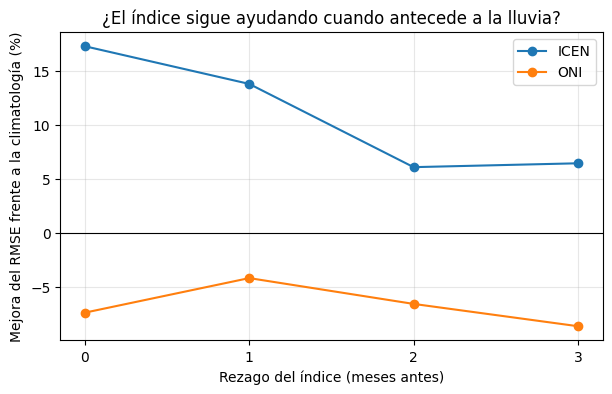

ICEN: mejora 17.3 % con rezago 0 y 6.4 % con rezago 3 (ventanas temporales, 5 pliegues).
ONI: mejora -7.4 % con rezago 0 y -8.7 % con rezago 3 (ventanas temporales, 5 pliegues).
Si la mejora cae a ~0 o se vuelve negativa con rezago, el modelo explica la lluvia pero todavía no sirve para pronosticarla.


In [ ]:
# 10.3 Índice con rezago: ¿sirve para pronosticar y no solo para explicar?
filas_lag = []
for ind in ['ICEN', 'ONI']:
    for L in [0, 1, 2, 3]:
        d = base_mensual[['fecha', 'pp_mm', 'mes']].copy()
        d['x'] = base_mensual[ind].shift(L)                       # índice de L meses antes
        d = d.dropna().reset_index(drop=True)
        r_base, r_mod = [], []
        for i_tr, i_te in TimeSeriesSplit(n_splits=5).split(d):
            tr, te = d.iloc[i_tr].copy(), d.iloc[i_te].copy()
            normal = tr.groupby('mes')['pp_mm'].mean()
            tr['normal_mes'], te['normal_mes'] = tr['mes'].map(normal), te['mes'].map(normal)
            rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42)
            rf.fit(tr[['normal_mes', 'x']], tr['pp_mm'])
            r_base.append(rmse(te['pp_mm'], te['normal_mes']))
            r_mod.append(rmse(te['pp_mm'], rf.predict(te[['normal_mes', 'x']])))
        filas_lag.append({'índice': ind, 'rezago_meses': L, 'RMSE_base_mm': np.mean(r_base), 'RMSE_RF_mm': np.mean(r_mod),
                          'mejora_%': 100 * (np.mean(r_base) - np.mean(r_mod)) / np.mean(r_base)})
tabla_lag = pd.DataFrame(filas_lag)
display(tabla_lag.round(1))
tabla_lag.to_csv(os.path.join(SALIDA, '13_validacion_rezagos_modelo.csv'), index=False)

fig, ax = plt.subplots(figsize=(7, 4))
for ind, g in tabla_lag.groupby('índice'):
    ax.plot(g['rezago_meses'], g['mejora_%'], marker='o', label=ind)
ax.axhline(0, color='k', lw=0.8)
ax.set(xlabel='Rezago del índice (meses antes)', ylabel='Mejora del RMSE frente a la climatología (%)',
       title='¿El índice sigue ayudando cuando antecede a la lluvia?', xticks=[0, 1, 2, 3])
ax.legend(); plt.show()

for ind, g in tabla_lag.groupby('índice'):
    g0, g3 = g[g['rezago_meses'] == 0].iloc[0], g[g['rezago_meses'] == 3].iloc[0]
    print(f"{ind}: mejora {g0['mejora_%']:.1f} % con rezago 0 y {g3['mejora_%']:.1f} % con rezago 3 (ventanas temporales, 5 pliegues).")
print("Si la mejora cae a ~0 o se vuelve negativa con rezago, el modelo explica la lluvia pero todavía no sirve para pronosticarla.")

**Cómo usar esta validación en la presentación.** El «mejor modelo» se justifica solo si **supera a la climatología en la mayoría de pliegues (10.1) y en la mayoría de eventos (10.2)**. Si la mejora desaparece con rezago (10.3), el modelo se presenta como herramienta para *explicar* la lluvia, no para pronosticarla. Las cifras exactas de estas tres celdas se leen de las tablas que genera cada ejecución.

## 11. Exportar datos limpios

In [ ]:
base_mensual.drop(columns=['outlier']).to_csv(os.path.join(SALIDA, '07_base_mensual_pisco_enso.csv'), index=False)
temporadas.to_csv(os.path.join(SALIDA, '06_lluvia_temporada_humeda.csv'))
print('Archivos guardados en', SALIDA, ':')
for f in sorted(os.listdir(SALIDA)):
    print(' -', f)

Archivos guardados en RESULTADOS_CDA_PIURA :
 - 01_resumen_estaciones.csv
 - 02_extremos_estaciones.csv
 - 03_estaciones_mensuales.csv
 - 04_indices_enso_limpios.csv
 - 06_lluvia_temporada_humeda.csv
 - 07_base_mensual_pisco_enso.csv
 - 08_correlacion_por_periodo.csv
 - 08b_h2_muestra_comun_bootstrap.csv
 - 09_correlaciones_rezagos.csv
 - 10_metricas_modelos.csv
 - 11_validacion_temporal_pliegues.csv
 - 12_validacion_por_evento.csv
 - 13_validacion_rezagos_modelo.csv
 - anomalias_mensuales_lluvia.csv
 - estacionalidad_mensual_lluvia.csv
 - lluvia_eventos_vs_normal.csv
 - temporadas_2022_2025_vs_normal.csv


## 12. Conclusiones, limitaciones y próximos pasos

### Conclusiones preliminares
1. **Estacionalidad:** la temporada dic-may concentra ≈ 89 % de la lluvia anual de Piura, con máximo en marzo (media 118 mm).
2. **Eventos:** 1982/83 y 1997/98 produjeron 4.3 a 4.8 veces la lluvia normal de la temporada húmeda, y 2017 y 2023 unas 2.6 veces; 1983 y 1998 concentran ≈ 37 % de los días extremos.
3. **Índices:** los costeros (**E**, correlación 0.75, e **ICEN**, 0.50) se asocian con la lluvia de temporada; **ONI (0.01) y C (−0.14) casi nada**. El ONI no detectó los eventos de 2017 y 2023.
4. **Cambio en el tiempo:** la relación con ONI y C se invierte tras 2000 y la de ICEN y E se debilita, con indicios pero sin confirmación estadística.
5. **Modelo base:** con un único corte 80/20, Random Forest con índices reduce el error en ≈ 19 % frente a la climatología (RMSE de 50.5 a 41.0 mm). Esa cifra **no basta para elegir el mejor modelo**: léase junto con la validación por ventanas temporales y por evento (secciones 10.1 a 10.3).

### Limitaciones
- PISCO corresponde al **departamento de Piura, no a la cuenca del río Piura**; para la cuenca se necesita la grilla original y el shapefile.
- Los resultados dependen de pocas temporadas extremas; con 18 a 44 temporadas, las diferencias entre periodos no son concluyentes.
- E y C terminan en 2020. ICEN y ONI se **limpiaron manualmente** (nov-2015 interpolado; dos filas del ONI recuperadas), marcadas en `ICEN_interpolado` y `ONI_reconstruido`; ninguna cae en dic-may, por lo que no entran en las medias por temporada, pero deben verificarse con la fuente original (sección 6.2).
- La temporada «2023» es solo dic 2022 – may 2023; la temporada 2023/24 se evalúa aparte (9.1).
- No hay **datos de caudal** en este análisis; la parte "caudales" es una fase posterior.
- El modelo usa el índice del mismo mes (explica, no pronostica).

### Próximos pasos
1. Incorporar las estaciones SENAMHI para validar PISCO (sección 8.5) y calcular PISCO sobre la cuenca.
2. Añadir caudales (ANA/SENAMHI) y evaluar rezagos lluvia-caudal.
3. Modelado: ajuste de hiperparámetros y comparación de más modelos (la validación temporal y por evento ya está en 10.1 a 10.3).
4. Ampliar el análisis de H2 con más temporadas cuando se actualicen E y C (los intervalos de confianza ya están en 8.3b).
5. Dashboard interactivo (Folium + Plotly) publicado en GitHub Pages.